In [26]:
%pip install -q ortools pandas numpy matplotlib

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
PROJECT_DIR = Path("/content/drive/MyDrive/tsp_precedence")
DATA_DIR    = PROJECT_DIR / "data"
LOG_DIR     = PROJECT_DIR / "logs"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR     = PROJECT_DIR / "figures"
for d in [DATA_DIR, LOG_DIR, RESULTS_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print("Folders ready under", PROJECT_DIR)

Mounted at /content/drive
Folders ready under /content/drive/MyDrive/tsp_precedence


In [3]:
%%writefile /content/drive/MyDrive/tsp_precedence/tsp_utils.py
"""Shared helpers for the precedence-TSP project. Import this everywhere."""
import json
import hashlib
import numpy as np

DISTANCE_SCALE = 1_000_000  # integer scaling for CP-SAT distances


def euclidean_distance(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)))


def tour_length(coords, tour):
    """Length of a closed tour with unrounded Euclidean distances."""
    coords = np.asarray(coords, dtype=float)
    return sum(euclidean_distance(coords[tour[i]], coords[tour[i + 1]])
               for i in range(len(tour) - 1))


def generate_instance(n, seed, n_precedences=None):
    """Random Euclidean instance with precedence pairs that agree with a hidden order."""
    rng = np.random.default_rng(seed)
    coords = rng.random((n, 2))
    perm = [int(c) for c in rng.permutation(np.arange(1, n))]
    hidden_order = [0] + perm + [0]
    rank = {c: i for i, c in enumerate(perm)}

    if n_precedences is None:
        n_precedences = n // 2
    max_pairs = (n - 1) * (n - 2) // 2
    n_precedences = min(n_precedences, max_pairs)

    pairs = set()
    while len(pairs) < n_precedences:
        a, b = (int(v) for v in rng.choice(np.arange(1, n), size=2, replace=False))
        if rank[a] > rank[b]:
            a, b = b, a
        pairs.add((a, b))
    precedences = sorted([list(p) for p in pairs])

    return {
        "n_cities": n,
        "seed": int(seed),
        "coordinates": coords.tolist(),
        "precedences": precedences,
        "n_precedences": len(precedences),
        "hidden_order": hidden_order,
    }


def check_tour(tour, n, precedences):
    """Strict diagnostic check. Returns {'valid': bool, 'errors': [...]}."""
    errors = []
    if not isinstance(tour, list):
        return {"valid": False, "errors": [{"type": "not_a_list"}]}
    if not all(isinstance(c, int) and not isinstance(c, bool) for c in tour):
        return {"valid": False, "errors": [{"type": "non_integer"}]}

    if len(tour) != n + 1:
        errors.append({"type": "wrong_length", "expected": n + 1, "got": len(tour)})
    if len(tour) == 0 or tour[0] != 0:
        errors.append({"type": "wrong_start", "got": tour[0] if tour else None})
    if len(tour) == 0 or tour[-1] != 0:
        errors.append({"type": "wrong_end", "got": tour[-1] if tour else None})

    out_of_range = sorted({c for c in tour if c < 0 or c >= n})
    if out_of_range:
        errors.append({"type": "out_of_range", "cities": out_of_range})

    interior = tour[1:-1] if len(tour) >= 2 else []
    counts = {}
    for c in interior:
        counts[c] = counts.get(c, 0) + 1
    missing = [c for c in range(1, n) if counts.get(c, 0) == 0]
    duplicates = sorted([c for c, k in counts.items() if k > 1 and 0 <= c < n])
    if 0 in counts:
        duplicates = sorted(set(duplicates) | {0})
    if missing:
        errors.append({"type": "missing", "cities": missing})
    if duplicates:
        errors.append({"type": "duplicate", "cities": duplicates})

    first_pos = {}
    for i, c in enumerate(interior):
        first_pos.setdefault(c, i)
    broken = []
    for a, b in precedences:
        if a in first_pos and b in first_pos and first_pos[a] > first_pos[b]:
            broken.append([a, b])
    if broken:
        errors.append({"type": "precedence", "pairs": broken})

    return {"valid": len(errors) == 0, "errors": errors}


def coordinate_fingerprint(coords):
    payload = json.dumps(coords, separators=(",", ":"))
    return hashlib.sha256(payload.encode()).hexdigest()


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

Writing /content/drive/MyDrive/tsp_precedence/tsp_utils.py


In [4]:
import sys, importlib
sys.path.append("/content/drive/MyDrive/tsp_precedence")
import tsp_utils
importlib.reload(tsp_utils)
from tsp_utils import *
print("tsp_utils loaded")

tsp_utils loaded


In [5]:
import json
SIZES = [10, 20, 30]
INSTANCES_PER_SIZE = 10
MASTER_SEED = 20261026
PRECEDENCE_RULE = "n // 2"

config = {
    "sizes": SIZES,
    "instances_per_size": INSTANCES_PER_SIZE,
    "master_seed": MASTER_SEED,
    "precedence_rule": PRECEDENCE_RULE,
    "distance_scale": DISTANCE_SCALE,
    "coordinates": "uniform in [0,1]^2",
    "depot": 0,
}
with open(DATA_DIR / "instance_config.json", "w") as f:
    json.dump(config, f, indent=2)
print(json.dumps(config, indent=2))

{
  "sizes": [
    10,
    20,
    30
  ],
  "instances_per_size": 10,
  "master_seed": 20261026,
  "precedence_rule": "n // 2",
  "distance_scale": 1000000,
  "coordinates": "uniform in [0,1]^2",
  "depot": 0
}


In [6]:
import numpy as np, pandas as pd

master_rng = np.random.default_rng(MASTER_SEED)
instances = []
for n in SIZES:
    for k in range(INSTANCES_PER_SIZE):
        seed = int(master_rng.integers(0, 2**31 - 1))
        inst = generate_instance(n, seed)
        inst["instance_id"] = f"n{n:02d}_{k:02d}"
        instances.append(inst)

out_path = DATA_DIR / "instances.jsonl"
with open(out_path, "w", encoding="utf-8") as f:
    for inst in instances:
        f.write(json.dumps(inst) + "\n")

summary = pd.DataFrame([{
    "instance_id": i["instance_id"], "n_cities": i["n_cities"],
    "n_precedences": i["n_precedences"], "seed": i["seed"],
    "hidden_order_length": tour_length(i["coordinates"], i["hidden_order"]),
} for i in instances])
summary.to_csv(DATA_DIR / "instances_summary.csv", index=False)
print(f"Saved {len(instances)} instances to {out_path}")
display(summary.groupby("n_cities").agg(
    instances=("instance_id", "count"),
    precedences=("n_precedences", "first"),
    mean_hidden_order_length=("hidden_order_length", "mean"),
))

Saved 30 instances to /content/drive/MyDrive/tsp_precedence/data/instances.jsonl


,instances,precedences,mean_hidden_order_length
n_cities,,,
10,10,5,5.286226
20,10,10,10.771618
30,10,15,15.865762


In [7]:
loaded = load_jsonl(DATA_DIR / "instances.jsonl")
assert len(loaded) == len(SIZES) * INSTANCES_PER_SIZE

for inst in loaded:
    res = check_tour(inst["hidden_order"], inst["n_cities"], inst["precedences"])
    assert res["valid"], (inst["instance_id"], res)

fps = [coordinate_fingerprint(i["coordinates"]) for i in loaded]
assert len(set(fps)) == len(fps), "duplicate coordinates found"
assert len({i["instance_id"] for i in loaded}) == len(loaded)

inst = loaded[0]; n = inst["n_cities"]; good = inst["hidden_order"]; P = inst["precedences"]
a, b = P[0]
tests = {
    "identity order (likely breaks precedence)": [0] + list(range(1, n)) + [0],
    "missing return to 0":   good[:-1],
    "one city dropped":      good[:2] + good[3:],
    "one city duplicated":   good[:2] + [good[1]] + good[3:],
    "precedence pair swapped": [c if c not in (a, b) else (b if c == a else a) for c in good],
    "out-of-range city":     good[:-2] + [n + 5, 0],
    "not starting at 0":     good[1:] + [good[1]],
}
for name, t in tests.items():
    r = check_tour(t, n, P)
    print(f"{name:45s} valid={r['valid']}  errors={[e['type'] for e in r['errors']]}")
    if name != "identity order (likely breaks precedence)":
        assert not r["valid"], name
print("\nAll Phase 1 checks passed.")

identity order (likely breaks precedence)     valid=False  errors=['precedence']
missing return to 0                           valid=False  errors=['wrong_length', 'wrong_end', 'missing']
one city dropped                              valid=False  errors=['wrong_length', 'missing']
one city duplicated                           valid=False  errors=['missing', 'duplicate']
precedence pair swapped                       valid=False  errors=['precedence']
out-of-range city                             valid=False  errors=['out_of_range', 'missing']
not starting at 0                             valid=False  errors=['wrong_start', 'wrong_end', 'missing', 'duplicate']

All Phase 1 checks passed.


In [ ]:
%%writefile /content/drive/MyDrive/tsp_precedence/cpsat_utils.py
"""CP-SAT model, solver, validator and baselines for precedence TSP."""
import time
import numpy as np
from ortools.sat.python import cp_model
from tsp_utils import DISTANCE_SCALE, check_tour, tour_length


def build_model(inst, fixed_tour=None, scale=DISTANCE_SCALE):
    n = inst["n_cities"]
    C = np.asarray(inst["coordinates"])
    D = [[int(round(np.linalg.norm(C[i] - C[j]) * scale)) for j in range(n)] for i in range(n)]
    m = cp_model.CpModel()
    x = {(i, j): m.NewBoolVar(f"x_{i}_{j}") for i in range(n) for j in range(n) if i != j}
    m.AddCircuit([(i, j, v) for (i, j), v in x.items()])
    pos = [m.NewIntVar(0, n - 1, f"pos_{i}") for i in range(n)]
    m.Add(pos[0] == 0)
    for (i, j), v in x.items():
        if j != 0:
            m.Add(pos[j] == pos[i] + 1).OnlyEnforceIf(v)
    for a, b in inst["precedences"]:
        m.Add(pos[a] < pos[b])
    if fixed_tour is not None:
        for k in range(len(fixed_tour) - 1):
            m.Add(x[fixed_tour[k], fixed_tour[k + 1]] == 1)
    else:
        m.Minimize(sum(D[i][j] * v for (i, j), v in x.items()))
    return m, x


def extract_tour(solver, x, n):
    succ = {i: j for (i, j), v in x.items() if solver.Value(v)}
    tour, cur = [0], 0
    for _ in range(n):
        cur = succ[cur]
        tour.append(cur)
    return tour


def solve_cpsat(inst, time_limit=60, workers=8):
    m, x = build_model(inst)
    s = cp_model.CpSolver()
    s.parameters.max_time_in_seconds = time_limit
    s.parameters.num_search_workers = workers
    s.parameters.random_seed = 0
    t0 = time.perf_counter()
    status = s.Solve(m)
    wall = time.perf_counter() - t0
    ok = status in (cp_model.OPTIMAL, cp_model.FEASIBLE)
    out = {"status": s.StatusName(status), "wall_seconds": wall,
           "objective_scaled": s.ObjectiveValue() if ok else None,
           "best_bound_scaled": s.BestObjectiveBound() if ok else None}
    if ok:
        out["tour"] = extract_tour(s, x, inst["n_cities"])
        out["length"] = tour_length(inst["coordinates"], out["tour"])
        out["bound_length"] = out["best_bound_scaled"] / DISTANCE_SCALE
    return out


def validate_with_cpsat(inst, tour, time_limit=10):
    
    n = inst["n_cities"]
    if (not isinstance(tour, list) or len(tour) != n + 1
            or not all(isinstance(c, int) and not isinstance(c, bool) and 0 <= c < n for c in tour)
            or tour[0] != 0 or tour[-1] != 0
            or any(tour[k] == tour[k + 1] for k in range(len(tour) - 1))):
        return False
    m, _ = build_model(inst, fixed_tour=tour)
    s = cp_model.CpSolver()
    s.parameters.max_time_in_seconds = time_limit
    status = s.Solve(m)
    return status in (cp_model.OPTIMAL, cp_model.FEASIBLE)


def nn_precedence(inst):
   
    n = inst["n_cities"]
    C = np.asarray(inst["coordinates"])
    prereq = {c: set() for c in range(n)}
    for a, b in inst["precedences"]:
        prereq[b].add(a)
    visited, tour, cur = {0}, [0], 0
    while len(visited) < n:
        cands = [c for c in range(1, n) if c not in visited and prereq[c] <= visited]
        nxt = min(cands, key=lambda c: np.linalg.norm(C[cur] - C[c]))
        tour.append(nxt); visited.add(nxt); cur = nxt
    tour.append(0)
    return tour

Writing /content/drive/MyDrive/tsp_precedence/cpsat_utils.py


In [9]:
import sys, importlib, os, json, time, platform
sys.path.append("/content/drive/MyDrive/tsp_precedence")
import cpsat_utils, tsp_utils
importlib.reload(tsp_utils); importlib.reload(cpsat_utils)
from tsp_utils import *
from cpsat_utils import *
import ortools, pandas as pd

TIME_LIMIT = 60
WORKERS = os.cpu_count()
print("CPU cores:", WORKERS, "| ortools:", ortools.__version__, "| python:", platform.python_version())

instances = load_jsonl(DATA_DIR / "instances.jsonl")
cp_path = RESULTS_DIR / "cpsat_results.jsonl"
done = {r["instance_id"] for r in load_jsonl(cp_path)} if cp_path.exists() else set()

for inst in instances:
    if inst["instance_id"] in done:
        continue
    r = solve_cpsat(inst, time_limit=TIME_LIMIT, workers=WORKERS)
    r.update({
        "instance_id": inst["instance_id"], "n_cities": inst["n_cities"],
        "time_limit": TIME_LIMIT, "workers": WORKERS,
        "py_valid": check_tour(r["tour"], inst["n_cities"], inst["precedences"])["valid"],
        "cpsat_valid": validate_with_cpsat(inst, r["tour"]),
    })
    with open(cp_path, "a") as f:
        f.write(json.dumps(r) + "\n")
    print(r["instance_id"], r["status"], round(r["wall_seconds"], 1), round(r["length"], 4), r["py_valid"], r["cpsat_valid"])

cp = pd.DataFrame(load_jsonl(cp_path))
cp.drop(columns=["tour"]).to_csv(RESULTS_DIR / "cpsat_results.csv", index=False)
display(cp.groupby("n_cities").agg(
    n=("instance_id", "count"),
    optimal=("status", lambda s: (s == "OPTIMAL").sum()),
    mean_len=("length", "mean"),
    mean_bound=("bound_length", "mean"),
    mean_seconds=("wall_seconds", "mean"),
    all_valid=("py_valid", "all"),
))

CPU cores: 2 | ortools: 9.15.6755 | python: 3.13.16
n10_00 OPTIMAL 0.0 3.1636 True True
n10_01 OPTIMAL 0.0 3.1175 True True
n10_02 OPTIMAL 0.1 4.0671 True True
n10_03 OPTIMAL 0.0 3.445 True True
n10_04 OPTIMAL 0.0 3.9717 True True
n10_05 OPTIMAL 0.0 2.5901 True True
n10_06 OPTIMAL 0.0 2.8803 True True
n10_07 OPTIMAL 0.0 3.2426 True True
n10_08 OPTIMAL 0.0 3.0518 True True
n10_09 OPTIMAL 0.1 2.7721 True True
n20_00 OPTIMAL 5.6 4.9353 True True
n20_01 OPTIMAL 4.1 4.9743 True True
n20_02 OPTIMAL 3.3 4.2562 True True
n20_03 OPTIMAL 0.7 4.8739 True True
n20_04 OPTIMAL 10.0 4.2368 True True
n20_05 OPTIMAL 0.6 3.6562 True True
n20_06 OPTIMAL 28.7 5.1796 True True
n20_07 OPTIMAL 14.3 4.5569 True True
n20_08 OPTIMAL 2.0 4.1731 True True
n20_09 OPTIMAL 3.1 4.3694 True True
n30_00 FEASIBLE 60.0 5.3749 True True
n30_01 FEASIBLE 60.0 5.7287 True True
n30_02 FEASIBLE 60.0 5.8163 True True
n30_03 FEASIBLE 60.0 5.9446 True True
n30_04 FEASIBLE 60.0 5.2238 True True
n30_05 FEASIBLE 60.0 5.3501 True Tru

,n,optimal,mean_len,mean_bound,mean_seconds,all_valid
n_cities,,,,,,
10,10,10,3.230184,3.230183,0.041827,True
20,10,10,4.521183,4.521182,7.240212,True
30,10,0,5.550808,3.998415,60.004135,True


In [10]:
rows = []
for inst in instances:
    t0 = time.perf_counter(); t = nn_precedence(inst); el = time.perf_counter() - t0
    rows.append({"instance_id": inst["instance_id"], "n_cities": inst["n_cities"],
                 "valid": check_tour(t, inst["n_cities"], inst["precedences"])["valid"],
                 "length": tour_length(inst["coordinates"], t),
                 "runtime_seconds": el, "tour": json.dumps(t)})
nn = pd.DataFrame(rows)
nn.to_csv(RESULTS_DIR / "nn_results.csv", index=False)

m = cp.merge(nn, on=["instance_id", "n_cities"], suffixes=("_cp", "_nn"))
m["nn_gap_pct"] = 100 * (m["length_nn"] / m["length_cp"] - 1)
display(m.groupby("n_cities").agg(nn_valid=("valid", "all"), mean_gap_pct=("nn_gap_pct", "mean"),
                                  max_gap_pct=("nn_gap_pct", "max")))
print("checker/CP-SAT agree on all CP-SAT tours:", bool((cp["py_valid"] == cp["cpsat_valid"]).all()))

,nn_valid,mean_gap_pct,max_gap_pct
n_cities,,,
10,True,12.143736,29.683249
20,True,23.331926,45.450379
30,True,19.607212,37.166749


checker/CP-SAT agree on all CP-SAT tours: True


In [11]:
%pip install -q google-genai

In [12]:
from google.colab import userdata
from google import genai

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
for m in client.models.list():
    if "flash" in m.name.lower():
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


In [13]:
from google.colab import userdata
from google import genai
from google.genai import types

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
MODEL_ID = "gemini-3.5-flash-lite"

resp = client.models.generate_content(
    model=MODEL_ID,
    contents='Return only this JSON object and nothing else: {"tour": [0, 2, 1, 0]}',
    config=types.GenerateContentConfig(
        thinking_config=types.ThinkingConfig(thinking_level="medium"),
    ),
)
print("TEXT:", repr(resp.text))
print("USAGE:", resp.usage_metadata)

TEXT: '{"tour": [0, 2, 1, 0]}'
USAGE: cache_tokens_details=None cached_content_token_count=None candidates_token_count=15 candidates_tokens_details=None prompt_token_count=25 prompt_tokens_details=[ModalityTokenCount(
  modality=<MediaModality.TEXT: 'TEXT'>,
  token_count=25
)] thoughts_token_count=116 tool_use_prompt_token_count=None tool_use_prompt_tokens_details=None total_token_count=156 traffic_type=None


In [ ]:
%%writefile /content/drive/MyDrive/tsp_precedence/tsp_utils.py

import json
import hashlib
import numpy as np

DISTANCE_SCALE = 1_000_000  # integer scaling for CP-SAT distances


def euclidean_distance(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)))


def tour_length(coords, tour):
    """Length of a closed tour with unrounded Euclidean distances."""
    coords = np.asarray(coords, dtype=float)
    return sum(euclidean_distance(coords[tour[i]], coords[tour[i + 1]])
               for i in range(len(tour) - 1))


def generate_instance(n, seed, n_precedences=None):
    """Random Euclidean instance with precedence pairs that agree with a hidden order."""
    rng = np.random.default_rng(seed)
    coords = rng.random((n, 2))
    perm = [int(c) for c in rng.permutation(np.arange(1, n))]
    hidden_order = [0] + perm + [0]
    rank = {c: i for i, c in enumerate(perm)}

    if n_precedences is None:
        n_precedences = n // 2
    max_pairs = (n - 1) * (n - 2) // 2
    n_precedences = min(n_precedences, max_pairs)

    pairs = set()
    while len(pairs) < n_precedences:
        a, b = (int(v) for v in rng.choice(np.arange(1, n), size=2, replace=False))
        if rank[a] > rank[b]:
            a, b = b, a
        pairs.add((a, b))
    precedences = sorted([list(p) for p in pairs])

    return {
        "n_cities": n,
        "seed": int(seed),
        "coordinates": coords.tolist(),
        "precedences": precedences,
        "n_precedences": len(precedences),
        "hidden_order": hidden_order,
    }


def check_tour(tour, n, precedences):
   
    errors = []
    if not isinstance(tour, list):
        return {"valid": False, "errors": [{"type": "not_a_list"}]}
    if not all(isinstance(c, int) and not isinstance(c, bool) for c in tour):
        return {"valid": False, "errors": [{"type": "non_integer"}]}

    if len(tour) != n + 1:
        errors.append({"type": "wrong_length", "expected": n + 1, "got": len(tour)})
    if len(tour) == 0 or tour[0] != 0:
        errors.append({"type": "wrong_start", "got": tour[0] if tour else None})
    if len(tour) == 0 or tour[-1] != 0:
        errors.append({"type": "wrong_end", "got": tour[-1] if tour else None})

    out_of_range = sorted({c for c in tour if c < 0 or c >= n})
    if out_of_range:
        errors.append({"type": "out_of_range", "cities": out_of_range})

    counts = {}
    for c in tour:
        if c != 0:
            counts[c] = counts.get(c, 0) + 1
    missing = [c for c in range(1, n) if c not in counts]
    duplicates = sorted(c for c, k in counts.items() if k > 1 and 0 <= c < n)
    if 0 in tour[1:-1]:
        duplicates = sorted(set(duplicates) | {0})
    if missing:
        errors.append({"type": "missing", "cities": missing})
    if duplicates:
        errors.append({"type": "duplicate", "cities": duplicates})

    first_pos = {}
    for i, c in enumerate(tour):
        if c != 0:
            first_pos.setdefault(c, i)
    broken = []
    for a, b in precedences:
        if a in first_pos and b in first_pos and first_pos[a] > first_pos[b]:
            broken.append([a, b])
    if broken:
        errors.append({"type": "precedence", "pairs": broken})

    return {"valid": len(errors) == 0, "errors": errors}


def coordinate_fingerprint(coords):
    payload = json.dumps(coords, separators=(",", ":"))
    return hashlib.sha256(payload.encode()).hexdigest()


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

Overwriting /content/drive/MyDrive/tsp_precedence/tsp_utils.py


In [ ]:
%%writefile /content/drive/MyDrive/tsp_precedence/llm_utils.py
"""Prompts, strict parser, feedback, resumable L0-L3 loop for precedence TSP."""
import json
import re
import time
import datetime
from tsp_utils import check_tour, tour_length
from cpsat_utils import validate_with_cpsat

K_ATTEMPTS = 5  # total attempts per feedback level (attempt 1 = the L1 answer)


#prompts
def _coord_lines(inst):
    return "\n".join(f"{i}: ({x:.4f}, {y:.4f})" for i, (x, y) in enumerate(inst["coordinates"]))


def prompt_l0(inst):
    n = inst["n_cities"]
    rules = "; ".join(f"city {a} before city {b}" for a, b in inst["precedences"])
    return (
        f"Solve this routing problem. There are {n} cities, numbered 0 to {n - 1}, "
        f"with coordinates (x, y):\n{_coord_lines(inst)}\n\n"
        f"Starting at city 0, visit every other city exactly once and then return to city 0, "
        f"keeping the total Euclidean distance as short as possible. "
        f"Some cities must be visited before others: {rules}.\n"
        f"Give the tour as a list of city numbers."
    )


def prompt_l1(inst):
    n = inst["n_cities"]
    rules = "\n".join(f"   - city {a} before city {b}" for a, b in inst["precedences"])
    return (
        "You are solving a Traveling Salesperson Problem with precedence constraints.\n\n"
        f"There are {n} cities, numbered 0 to {n - 1}. City 0 is the depot. "
        f"Coordinates (x, y):\n{_coord_lines(inst)}\n\n"
        "Rules. A tour that breaks any rule is invalid:\n"
        "1. The tour starts at city 0.\n"
        f"2. The tour visits each of the cities 1 to {n - 1} exactly once.\n"
        "3. The tour ends by returning to city 0. City 0 appears only as the first and the last entry.\n"
        f"4. The tour has exactly {n + 1} entries.\n"
        "5. Precedence: for every pair \"a before b\" below, city a must appear earlier "
        "in the tour than city b:\n"
        f"{rules}\n\n"
        "Objective: among valid tours, make the total Euclidean distance as short as possible.\n\n"
        "Output format: return ONLY a JSON object, with no other text: {\"tour\": [0, ..., 0]}"
    )


FEEDBACK_L2 = 'Your tour is invalid. Try again. Return only the JSON object {"tour": [0, ..., 0]}.'


def feedback_l3(inst, rec):
    """Specific feedback built from the checker's diagnosis of the previous reply."""
    n = inst["n_cities"]
    lines = []
    if rec["parsed_tour"] is None:
        lines.append("Your reply could not be read as a JSON object with a \"tour\" list of integers.")
    else:
        for e in rec["errors"]:
            t = e["type"]
            if t == "non_integer":
                lines.append("Every entry of the tour must be an integer city number.")
            elif t == "wrong_length":
                lines.append(f"The tour has {e['got']} entries but must have exactly {e['expected']}.")
            elif t == "wrong_start":
                lines.append("The tour must start at city 0.")
            elif t == "wrong_end":
                lines.append("The tour must end at city 0.")
            elif t == "out_of_range":
                lines.append(f"These city numbers do not exist: {e['cities']}. Valid cities are 0 to {n - 1}.")
            elif t == "missing":
                lines.append(f"These cities are never visited: {e['cities']}.")
            elif t == "duplicate":
                lines.append(f"These cities appear more than once (city 0 may only be first and last): {e['cities']}.")
            elif t == "precedence":
                for a, b in e["pairs"]:
                    lines.append(f"City {a} must be visited before city {b}, but your tour visits {b} first.")
    body = "\n".join(f"- {s}" for s in lines)
    return ("Your tour is invalid:\n" + body +
            "\nFix these problems and try again. Return only the JSON object {\"tour\": [0, ..., 0]}.")


#parser
def parse_reply(text):
    """Strict. Returns (tour_or_None, parse_error_or_None). No repair of any kind."""
    if text is None or not text.strip():
        return None, "empty_reply"
    s = text.strip()
    m = re.fullmatch(r"```(?:json)?\s*(.*?)\s*```", s, flags=re.S | re.I)
    if m:
        s = m.group(1).strip()
    try:
        obj = json.loads(s)
    except Exception:
        return None, "not_json"
    if isinstance(obj, dict):
        if "tour" not in obj:
            return None, "no_tour_key"
        obj = obj["tour"]
    if not isinstance(obj, list):
        return None, "tour_not_a_list"
    return obj, None


#model call
class DailyQuotaExceeded(RuntimeError):
    pass


def make_gemini_caller(client, model_id, thinking_level, max_retries=6):
    """Returns caller(messages) -> dict. messages = [(role, text)], role in {'user','model'}."""
    from google.genai import types

    def caller(messages):
        contents = [types.Content(role=r, parts=[types.Part(text=t)]) for r, t in messages]
        cfg = types.GenerateContentConfig(
            thinking_config=types.ThinkingConfig(thinking_level=thinking_level))
        retries = 0
        for attempt in range(max_retries):
            try:
                t0 = time.perf_counter()
                resp = client.models.generate_content(model=model_id, contents=contents, config=cfg)
                latency = time.perf_counter() - t0
                u = resp.usage_metadata
                fr = None
                try:
                    fr = str(resp.candidates[0].finish_reason)
                except Exception:
                    pass
                return {"text": resp.text, "latency": latency, "retries": retries, "finish_reason": fr,
                        "input_tokens": getattr(u, "prompt_token_count", None),
                        "output_tokens": getattr(u, "candidates_token_count", None),
                        "thinking_tokens": getattr(u, "thoughts_token_count", None)}
            except Exception as e:
                msg = str(e)
                transient = any(k in msg for k in ("429", "RESOURCE_EXHAUSTED", "500", "503", "UNAVAILABLE", "DEADLINE"))
                if not transient:
                    raise
                if "PerDay" in msg or "per day" in msg.lower():
                    raise DailyQuotaExceeded(msg)
                retries += 1
                wait = min(90, 10 * 2 ** attempt)
                print(f"  transient API error ({msg[:80]}...); waiting {wait}s")
                time.sleep(wait)
        raise RuntimeError("API failed after retries")
    return caller


#logging
class CallLog:
    def __init__(self, path):
        self.path = path
        self.records = {}
        if path.exists():
            with open(path, encoding="utf-8") as f:
                for line in f:
                    if line.strip():
                        r = json.loads(line)
                        self.records[(r["instance_id"], r["level"], r["attempt"])] = r

    def get(self, key):
        return self.records.get(key)

    def add(self, rec):
        key = (rec["instance_id"], rec["level"], rec["attempt"])
        assert key not in self.records, key
        with open(self.path, "a", encoding="utf-8") as f:
            f.write(json.dumps(rec) + "\n")
            f.flush()
        self.records[key] = rec


#loop
class Runner:
    def __init__(self, caller, log, model_id, thinking_level, pause=5.0, max_new_calls=None):
        self.caller, self.log = caller, log
        self.model_id, self.thinking_level = model_id, thinking_level
        self.pause, self.max_new_calls = pause, max_new_calls
        self.new_calls = 0

    def call(self, inst, level, attempt, messages):
        key = (inst["instance_id"], level, attempt)
        cached = self.log.get(key)
        if cached is not None:
            return cached
        if self.max_new_calls is not None and self.new_calls >= self.max_new_calls:
            raise DailyQuotaExceeded("max_new_calls reached (self-imposed cap)")
        res = self.caller(messages)
        self.new_calls += 1
        n = inst["n_cities"]
        tour, perr = parse_reply(res["text"])
        if tour is None:
            chk = {"valid": False, "errors": [{"type": perr}]}
            cp_valid = False
        else:
            chk = check_tour(tour, n, inst["precedences"])
            cp_valid = validate_with_cpsat(inst, tour)
        rec = {
            "instance_id": inst["instance_id"], "n_cities": n, "level": level, "attempt": attempt,
            "user_message": messages[-1][1], "raw_reply": res["text"] or "",
            "parsed_tour": tour, "parse_error": perr,
            "py_valid": chk["valid"], "cpsat_valid": cp_valid,
            "error_types": [e["type"] for e in chk["errors"]], "errors": chk["errors"],
            "tour_length": tour_length(inst["coordinates"], tour) if chk["valid"] else None,
            "input_tokens": res.get("input_tokens"), "output_tokens": res.get("output_tokens"),
            "thinking_tokens": res.get("thinking_tokens"), "latency_seconds": res.get("latency"),
            "retries": res.get("retries"), "finish_reason": res.get("finish_reason"),
            "model_id": self.model_id, "thinking_level": self.thinking_level,
            "timestamp": datetime.datetime.now(datetime.timezone.utc).isoformat(),
        }
        if rec["py_valid"] != rec["cpsat_valid"]:
            print(f"  !! checker/CP-SAT DISAGREE on {key}")
        self.log.add(rec)
        time.sleep(self.pause)
        return rec

    @staticmethod
    def _history(chain):
        h = []
        for r in chain:
            h += [("user", r["user_message"]), ("model", r["raw_reply"] or "[empty reply]")]
        return h

    def run_instance(self, inst):
        self.call(inst, "L0", 1, [("user", prompt_l0(inst))])
        r1 = self.call(inst, "L1", 1, [("user", prompt_l1(inst))])
        for level in ("L2", "L3"):
            chain, last = [r1], r1
            for attempt in range(2, K_ATTEMPTS + 1):
                if last["py_valid"]:
                    break
                fb = FEEDBACK_L2 if level == "L2" else feedback_l3(inst, last)
                last = self.call(inst, level, attempt, self._history(chain) + [("user", fb)])
                chain.append(last)

    def summary_line(self, inst):
        iid, parts = inst["instance_id"], []
        for level in ("L0", "L1", "L2", "L3"):
            recs = [self.log.get((iid, level, a)) for a in range(1, K_ATTEMPTS + 1)]
            recs = [r for r in recs if r]
            if level in ("L2", "L3"):
                recs = [self.log.get((iid, "L1", 1))] + recs
            first_ok = next((i + 1 for i, r in enumerate(recs) if r["py_valid"]), None)
            parts.append(f"{level}:{'ok@' + str(first_ok) if first_ok else 'FAIL'}")
        return f"{iid}  " + "  ".join(parts)

Writing /content/drive/MyDrive/tsp_precedence/llm_utils.py


In [16]:
import sys, importlib
sys.path.append("/content/drive/MyDrive/tsp_precedence")
import tsp_utils, cpsat_utils, llm_utils
for mod in (tsp_utils, cpsat_utils, llm_utils):
    importlib.reload(mod)
from tsp_utils import *
from llm_utils import *

from google.colab import userdata
from google import genai
client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

MODEL_ID = "gemini-3.5-flash-lite"
THINKING_LEVEL = "medium"
PAUSE_SECONDS = 5          # stays under 15 requests/minute
PILOT_PER_SIZE = 2

instances = load_jsonl(DATA_DIR / "instances.jsonl")
pilot = [i for n in (10, 20, 30) for i in [j for j in instances if j["n_cities"] == n][:PILOT_PER_SIZE]]

log = CallLog(LOG_DIR / "llm_calls.jsonl")
caller = make_gemini_caller(client, MODEL_ID, THINKING_LEVEL)
runner = Runner(caller, log, MODEL_ID, THINKING_LEVEL, pause=PAUSE_SECONDS, max_new_calls=80)

for inst in pilot:
    runner.run_instance(inst)
    print(runner.summary_line(inst), flush=True)
print("new API calls this run:", runner.new_calls)

n10_00  L0:FAIL  L1:FAIL  L2:ok@2  L3:ok@2
n10_01  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_00  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
n20_01  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
n30_00  L0:FAIL  L1:FAIL  L2:ok@3  L3:ok@2
n30_01  L0:FAIL  L1:FAIL  L2:ok@2  L3:ok@2
new API calls this run: 19


In [17]:
import pandas as pd
recs = pd.DataFrame(list(log.records.values()))
print(recs.groupby(["level", "attempt"]).agg(
    calls=("py_valid", "size"), valid=("py_valid", "sum"),
    mean_latency=("latency_seconds", "mean"), mean_think_tokens=("thinking_tokens", "mean")))
print("checker/CP-SAT disagreements:", int((recs["py_valid"] != recs["cpsat_valid"]).sum()))
print("parse errors:", recs["parse_error"].value_counts(dropna=True).to_dict())
for _, r in recs[~recs["py_valid"]].head(4).iterrows():
    print("=" * 60, r["instance_id"], r["level"], r["attempt"], r["error_types"])
    print(r["raw_reply"][:300])

               calls  valid  mean_latency  mean_think_tokens
level attempt                                               
L0    1            6      2     11.325255        4760.666667
L1    1            6      3      9.115313        4491.400000
L2    2            3      2      4.150881        1190.666667
      3            1      1      6.229032        2392.000000
L3    2            3      3      5.977729        2487.333333
checker/CP-SAT disagreements: 0
parse errors: {'not_json': 5}
============================================================ n10_00 L0 1 ['not_json']
To solve this routing problem, we need to find the shortest TSP tour starting and ending at city 0 that visits all other cities once while respecting the given precedence constraints:
- 4 before 2
- 2 before 6
- 5 before 1
- 9 before 3
- 9 before 7

By evaluating the Euclidean distances between the 
============================================================ n10_00 L1 1 ['not_json']
{tsp: [0, 4, 5, 1, 8, 2, 6, 9, 3, 7, 0

In [18]:
import sys, importlib
sys.path.append("/content/drive/MyDrive/tsp_precedence")
import tsp_utils, cpsat_utils, llm_utils
for mod in (tsp_utils, cpsat_utils, llm_utils):
    importlib.reload(mod)
from tsp_utils import *
from llm_utils import *

from google.colab import userdata
from google import genai
client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

MODEL_ID = "gemini-3.5-flash-lite"
THINKING_LEVEL = "medium"
PAUSE_SECONDS = 5

instances = load_jsonl(DATA_DIR / "instances.jsonl")
log = CallLog(LOG_DIR / "llm_calls.jsonl")
caller = make_gemini_caller(client, MODEL_ID, THINKING_LEVEL)
runner = Runner(caller, log, MODEL_ID, THINKING_LEVEL, pause=PAUSE_SECONDS, max_new_calls=300)

for inst in instances:
    try:
        runner.run_instance(inst)
    except DailyQuotaExceeded as e:
        print("STOPPED:", e)
        break
    print(runner.summary_line(inst), flush=True)

print("new API calls this run:", runner.new_calls, "| total logged:", len(log.records))

n10_00  L0:FAIL  L1:FAIL  L2:ok@2  L3:ok@2
n10_01  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n10_02  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n10_03  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
n10_04  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n10_05  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n10_06  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n10_07  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n10_08  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n10_09  L0:FAIL  L1:FAIL  L2:ok@2  L3:ok@2
n20_00  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
n20_01  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
n20_02  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_03  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_04  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_05  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_06  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_07  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_08  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n20_09  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n30_00  L0:FAIL  L1:FAIL  L2:ok@3  L3:ok@2
n30_01  L0:FAIL  L1:FAIL  L2:ok@2  L3:ok@2
n30_02  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
n30_03  L0:

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
model: ['gemini-3.5-flash-lite'] | thinking: ['medium']
calls logged: 78 | instances: 30 of 30
first call: 2026-10-26T09:00:39.199990+00:00 | last call: 2026-10-26T09:20:30.606078+00:00
checker/CP-SAT disagreements: 0

== Validity (L0, L1: first attempt; L2, L3: within 5 attempts) ==


n,10,20,30,all
level,,,,
L0,1/10 (10%),2/10 (20%),1/10 (10%),4/30 (13%)
L1,8/10 (80%),10/10 (100%),5/10 (50%),23/30 (77%)
L2,10/10 (100%),10/10 (100%),10/10 (100%),30/30 (100%)
L3,10/10 (100%),10/10 (100%),10/10 (100%),30/30 (100%)



== Effort: attempts to first valid tour (attempt 1 = the L1 answer) ==


,level,n,instances,solved,mean_attempts,median_attempts,max_attempts,first_try_valid
0,L2,10,10,10,1.2,1.0,2.0,8
1,L2,20,10,10,1.0,1.0,1.0,10
2,L2,30,10,10,1.9,1.5,5.0,5
3,L3,10,10,10,1.2,1.0,2.0,8
4,L3,20,10,10,1.0,1.0,1.0,10
5,L3,30,10,10,1.5,1.5,2.0,5


Instances by attempts needed:


...

Mean tokens per solved instance-level (L2/L3 include the L1 first attempt):


input_tokens                        output_tokens                       \
level           L0     L1      L2      L3            L0     L1     L2     L3   
n                                                                              
10           307.0  430.0   529.0   534.0          33.0   49.0   54.0   54.0   
20           558.0  693.0   693.0   693.0          73.0  100.0  100.0  100.0   
30           810.0  954.0  3436.0  1801.0         113.0  142.0  848.0  446.0   

      thinking_tokens                          
level              L0      L1      L2      L3  
n                                              
10             5514.0  4476.0  5162.0  5105.0  
20             3451.0  2817.0  2817.0  2817.0  
30             4658.0  4194.0  3783.0  3960.0


== Failure categories (a failed attempt can show several) ==


,failed_attempts,format,structure,coverage,precedence
L0 first attempt,26,11,15,2,0
L1 first attempt,7,4,0,0,3
L2 retries,4,3,0,0,1


error_types,missing,not_json,precedence,wrong_end,wrong_length
group,,,,,
L0 first attempt,2,11,0,15,15
L1 first attempt,0,4,3,0,0
L2 retries,0,3,1,0,0


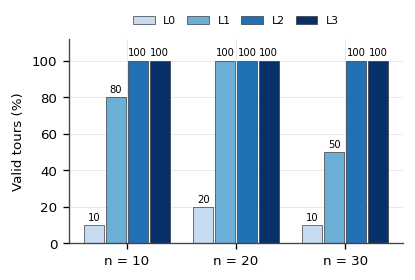

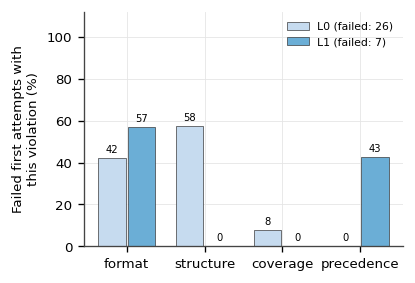

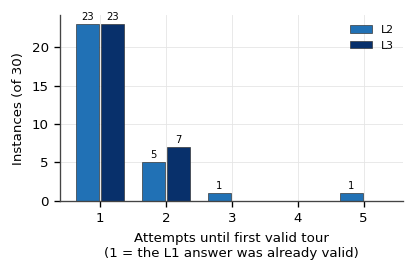

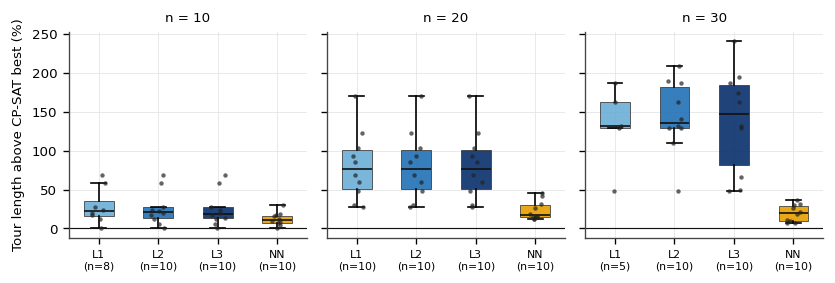

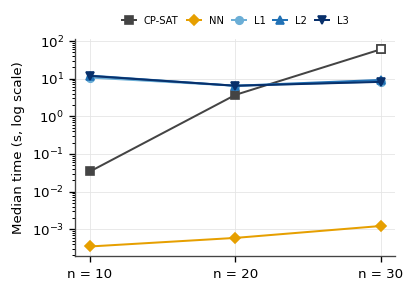

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys
sys.path.append("/content/drive/MyDrive/tsp_precedence")
from pathlib import Path
from tsp_utils import load_jsonl
PROJECT_DIR = Path("/content/drive/MyDrive/tsp_precedence")
DATA_DIR, LOG_DIR = PROJECT_DIR / "data", PROJECT_DIR / "logs"
RESULTS_DIR, FIG_DIR = PROJECT_DIR / "results", PROJECT_DIR / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

K = 5
LEVELS = ["L0", "L1", "L2", "L3"]
SIZES = [10, 20, 30]
COLORS = {"L0": "#c6dbef", "L1": "#6baed6", "L2": "#2171b5", "L3": "#08306b", "NN": "#E69F00"}
CATEGORY = {
    "not_json": "format", "empty_reply": "format", "no_tour_key": "format",
    "tour_not_a_list": "format", "not_a_list": "format", "non_integer": "format",
    "wrong_length": "structure", "wrong_start": "structure", "wrong_end": "structure",
    "out_of_range": "structure", "missing": "coverage", "duplicate": "coverage",
    "precedence": "precedence",
}
CAT_ORDER = ["format", "structure", "coverage", "precedence"]
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444", "axes.grid": True, "grid.color": "#e5e5e5",
                     "grid.linewidth": 0.5, "axes.axisbelow": True, "figure.dpi": 120})

# ---------------------------------------------------------------- load
df = pd.DataFrame(load_jsonl(LOG_DIR / "llm_calls.jsonl"))
cp = pd.DataFrame(load_jsonl(RESULTS_DIR / "cpsat_results.jsonl")).set_index("instance_id")
nn = pd.read_csv(RESULTS_DIR / "nn_results.csv").set_index("instance_id")
instances = {i["instance_id"]: i for i in load_jsonl(DATA_DIR / "instances.jsonl")}

print("model:", sorted(df["model_id"].unique()), "| thinking:", sorted(df["thinking_level"].unique()))
print("calls logged:", len(df), "| instances:", df["instance_id"].nunique(), "of", len(instances))
print("first call:", df["timestamp"].min(), "| last call:", df["timestamp"].max())
print("checker/CP-SAT disagreements:", int((df["py_valid"] != df["cpsat_valid"]).sum()))

# ------------------------------------------------- one row per instance x level
rows = []
for iid, g in df.groupby("instance_id"):
    g = g.set_index(["level", "attempt"])
    l1 = g.loc[("L1", 1)]

    def chain_for(level):
        if level in ("L0", "L1"):
            return [g.loc[(level, 1)]]
        ch, a = [l1], 2
        while (level, a) in g.index and not ch[-1]["py_valid"]:
            ch.append(g.loc[(level, a)]); a += 1
        return ch

    for level in LEVELS:
        ch = chain_for(level)
        fv = next((i for i, r in enumerate(ch) if r["py_valid"]), None)
        incomplete = fv is None and len(ch) < (1 if level in ("L0", "L1") else K)
        assert not incomplete, f"incomplete chain: {iid} {level}"
        lat = sum((r["latency_seconds"] or 0) for r in ch)
        rows.append({
            "instance_id": iid, "n": int(l1["n_cities"]), "level": level,
            "solved": fv is not None,
            "attempts_to_valid": (fv + 1) if fv is not None else np.nan,
            "attempts_used": len(ch),
            "llm_seconds": lat,
            "input_tokens": sum((r["input_tokens"] or 0) for r in ch),
            "output_tokens": sum((r["output_tokens"] or 0) for r in ch),
            "thinking_tokens": sum((r["thinking_tokens"] or 0) for r in ch),
            "tour_length": ch[fv]["tour_length"] if fv is not None else np.nan,
        })
R = pd.DataFrame(rows)
R["cp_length"] = R["instance_id"].map(cp["length"])
R["gap_pct"] = 100 * (R["tour_length"] / R["cp_length"] - 1)

#Table 1: validity
t1 = (R.groupby(["level", "n"])["solved"].agg(["sum", "count"]).reset_index()
        .assign(pct=lambda d: 100 * d["sum"] / d["count"]))
overall = (R.groupby("level")["solved"].agg(["sum", "count"]).reset_index()
             .assign(n="all", pct=lambda d: 100 * d["sum"] / d["count"]))
t1 = pd.concat([t1, overall], ignore_index=True)
t1_wide = t1.assign(cell=lambda d: d["sum"].astype(int).astype(str) + "/" + d["count"].astype(str)
                    + " (" + d["pct"].round(0).astype(int).astype(str) + "%)") \
            .pivot(index="level", columns="n", values="cell")[SIZES + ["all"]]
t1_wide.to_csv(RESULTS_DIR / "table_validity.csv")
print("\n== Validity (L0, L1: first attempt; L2, L3: within 5 attempts) ==")
display(t1_wide)

#Table 2: effort
fb = R[R["level"].isin(["L2", "L3"])]
t2 = (fb.groupby(["level", "n"]).agg(
        instances=("instance_id", "count"), solved=("solved", "sum"),
        mean_attempts=("attempts_to_valid", "mean"), median_attempts=("attempts_to_valid", "median"),
        max_attempts=("attempts_to_valid", "max"),
        first_try_valid=("attempts_to_valid", lambda s: int((s == 1).sum()))).reset_index())
t2.to_csv(RESULTS_DIR / "table_effort.csv", index=False)
print("\n== Effort: attempts to first valid tour (attempt 1 = the L1 answer) ==")
display(t2.round(2))
dist = (fb.dropna(subset=["attempts_to_valid"]).groupby(["level", "attempts_to_valid"])
          .size().unstack(fill_value=0).reindex(columns=range(1, K + 1), fill_value=0))
print("Instances by attempts needed:"); display(dist)

#Table 3: quality
nn_rows = pd.DataFrame({"instance_id": nn.index, "n": nn["n_cities"].values, "level": "NN",
                        "tour_length": nn["length"].values, "solved": nn["valid"].values})
nn_rows["cp_length"] = nn_rows["instance_id"].map(cp["length"])
nn_rows["gap_pct"] = 100 * (nn_rows["tour_length"] / nn_rows["cp_length"] - 1)
Q = pd.concat([R[["instance_id", "n", "level", "solved", "tour_length", "cp_length", "gap_pct"]], nn_rows],
              ignore_index=True)
Q = Q[Q["solved"] & Q["gap_pct"].notna()]
t3 = (Q.groupby(["n", "level"])["gap_pct"].agg(valid_tours="count", mean_gap="mean", median_gap="median",
                                               min_gap="min", max_gap="max",
                                               shorter_than_cpsat=lambda s: int((s < -1e-9).sum()))
        .reset_index())
t3.to_csv(RESULTS_DIR / "table_quality.csv", index=False)
print("\n== Tour quality: % above CP-SAT best tour (valid tours only; negative = shorter than CP-SAT's) ==")
display(t3.round(2))

#Table 4: time
cp_t = cp.groupby("n_cities")["wall_seconds"].median().rename("cpsat_median_s")
cp_opt = cp.groupby("n_cities")["status"].apply(lambda s: f"{int((s == 'OPTIMAL').sum())}/{len(s)} proven").rename("cpsat_status")
llm_t = (R[R["solved"]].groupby(["n", "level"])["llm_seconds"].median().unstack().add_suffix("_median_s"))
nn_t = nn.groupby("n_cities")["runtime_seconds"].median().rename("NN_median_s")
tok = (R[R["solved"]].groupby(["n", "level"])[["input_tokens", "output_tokens", "thinking_tokens"]]
         .mean().round(0).unstack())
t4 = pd.concat([cp_t, cp_opt, nn_t, llm_t], axis=1)
t4.index.name = "n"
t4.to_csv(RESULTS_DIR / "table_time.csv")
tok.to_csv(RESULTS_DIR / "table_tokens.csv")
print("\n== Time (seconds, medians; LLM = sum of API latencies until first valid tour, pauses excluded) ==")
display(t4.round(3))
print("Mean tokens per solved instance-level (L2/L3 include the L1 first attempt):"); display(tok)

#Table 5: why attempts fail
f = df[~df["py_valid"]].copy()
f["group"] = np.where((f["level"].isin(["L0", "L1"])) & (f["attempt"] == 1), f["level"] + " first attempt",
                      np.where(f["attempt"] >= 2, f["level"] + " retries", None))
f = f[f["group"].notna()]
f["cats"] = f["error_types"].apply(lambda ts: sorted({CATEGORY.get(t, "other") for t in ts}))
cat_counts = {}
for grp, gg in f.groupby("group"):
    n_fail = len(gg)
    cat_counts[grp] = {"failed_attempts": n_fail,
                       **{c: int(gg["cats"].apply(lambda cs, c=c: c in cs).sum()) for c in CAT_ORDER}}
t5 = pd.DataFrame(cat_counts).T
t5.to_csv(RESULTS_DIR / "table_failure_categories.csv")
print("\n== Failure categories (a failed attempt can show several) ==")
display(t5)
err_counts = (f.explode("error_types").groupby(["group", "error_types"]).size().unstack(fill_value=0))
err_counts.to_csv(RESULTS_DIR / "table_error_types.csv")
display(err_counts)

# figures
# Fig 1: validity by level and size
fig, ax = plt.subplots(figsize=(3.5, 2.4))
w = 0.2
for j, lv in enumerate(LEVELS):
    vals = [100 * R[(R.level == lv) & (R.n == n)]["solved"].mean() for n in SIZES]
    xs = np.arange(len(SIZES)) + (j - 1.5) * w
    ax.bar(xs, vals, w * 0.92, color=COLORS[lv], edgecolor="#333", linewidth=0.4, label=lv)
    for x, v in zip(xs, vals):
        ax.text(x, v + 1.5, f"{v:.0f}", ha="center", va="bottom", fontsize=6)
ax.set_xticks(range(len(SIZES))); ax.set_xticklabels([f"n = {n}" for n in SIZES])
ax.set_ylabel("Valid tours (%)"); ax.set_ylim(0, 112)
ax.legend(ncol=4, frameon=False, fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, 1.16), columnspacing=1)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_validity.png", dpi=300); plt.show()

# Fig 2: why first attempts fail (L0 vs L1)
fig, ax = plt.subplots(figsize=(3.5, 2.4))
w = 0.38
for j, lv in enumerate(["L0", "L1"]):
    grp = f"{lv} first attempt"
    if grp not in t5.index:
        continue
    tot = t5.loc[grp, "failed_attempts"]
    vals = [100 * t5.loc[grp, c] / tot for c in CAT_ORDER]
    xs = np.arange(len(CAT_ORDER)) + (j - 0.5) * w
    ax.bar(xs, vals, w * 0.92, color=COLORS[lv], edgecolor="#333", linewidth=0.4,
           label=f"{lv} (failed: {int(tot)})")
    for x, v in zip(xs, vals):
        ax.text(x, v + 1.5, f"{v:.0f}", ha="center", va="bottom", fontsize=6)
ax.set_xticks(range(len(CAT_ORDER))); ax.set_xticklabels(CAT_ORDER)
ax.set_ylabel("Failed first attempts with\nthis violation (%)"); ax.set_ylim(0, 112)
ax.legend(frameon=False, fontsize=6.5, loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_failure_types.png", dpi=300); plt.show()

# Fig 3 (fixed label)
fig, ax = plt.subplots(figsize=(3.5, 2.3))
w = 0.38
for j, lv in enumerate(["L2", "L3"]):
    vals = [int(dist.loc[lv, a]) if lv in dist.index else 0 for a in range(1, K + 1)]
    xs = np.arange(1, K + 1) + (j - 0.5) * w
    ax.bar(xs, vals, w * 0.92, color=COLORS[lv], edgecolor="#333", linewidth=0.4, label=lv)
    for x, v in zip(xs, vals):
        if v:
            ax.text(x, v + 0.3, str(v), ha="center", va="bottom", fontsize=6)
ax.set_xticks(range(1, K + 1))
ax.set_xlabel("Attempts until first valid tour\n(1 = the L1 answer was already valid)")
ax.set_ylabel("Instances (of 30)")
ax.legend(frameon=False, fontsize=6.5)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_attempts.png", dpi=300); plt.show()

# Fig 4: gap to CP-SAT
order = ["L1", "L2", "L3", "NN"]
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.4), sharey=True)
rng_j = np.random.default_rng(0)
for ax, n in zip(axes, SIZES):
    data, labels = [], []
    for m in order:
        s = Q[(Q.n == n) & (Q.level == m)]["gap_pct"].values
        data.append(s); labels.append(f"{m}\n(n={len(s)})")
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops={"color": "#111", "linewidth": 1})
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(COLORS[m]); patch.set_edgecolor("#333"); patch.set_linewidth(0.5); patch.set_alpha(0.9)
    for i, s in enumerate(data):
        ax.scatter(1 + i + rng_j.uniform(-0.12, 0.12, len(s)), s, s=7, color="#222", alpha=0.7, zorder=3, linewidths=0)
    ax.axhline(0, color="#111", linewidth=0.7)
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(labels, fontsize=6.5)
    ax.set_title(f"n = {n}", fontsize=8)
axes[0].set_ylabel("Tour length above CP-SAT best (%)")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_gap.png", dpi=300); plt.show()

# Fig 5 lines + markers instead of bars on a log axis
fig, ax = plt.subplots(figsize=(3.5, 2.5))
series = [("CP-SAT", t4["cpsat_median_s"], "#444444", "s"), ("NN", t4["NN_median_s"], COLORS["NN"], "D"),
          ("L1", t4["L1_median_s"], COLORS["L1"], "o"), ("L2", t4["L2_median_s"], COLORS["L2"], "^"),
          ("L3", t4["L3_median_s"], COLORS["L3"], "v")]
for name, ser, col, mk in series:
    ys = [ser.get(n, np.nan) for n in SIZES]
    ax.plot(SIZES, ys, color=col, marker=mk, markersize=4.5, linewidth=1.2, label=name)
# n = 30: CP-SAT hit its 60 s limit in every instance (not time-to-optimal) -> hollow marker
ax.plot([30], [t4["cpsat_median_s"].get(30, np.nan)], marker="s", markersize=5, markerfacecolor="white",
        markeredgecolor="#444444", linestyle="none")
ax.set_yscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([f"n = {n}" for n in SIZES])
ax.set_ylabel("Median time (s, log scale)")
ax.legend(ncol=5, frameon=False, fontsize=6, loc="upper center", bbox_to_anchor=(0.5, 1.15), columnspacing=0.8,
          handlelength=1.4)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_time.png", dpi=300); plt.show()

In [21]:
fail = df[(~df["py_valid"]) & (((df["level"] == "L1") & (df["attempt"] == 1)) | (df["attempt"] >= 2))]
for _, r in fail.iterrows():
    print("=" * 70)
    print(r["instance_id"], r["level"], "attempt", r["attempt"], r["error_types"], "| parse_error:", r["parse_error"])
    print(r["raw_reply"].strip()[:250].replace("\n", " "))

# Post-hoc diagnostic (NOT a scoring change): L0 replies that parsed to a list
from tsp_utils import check_tour
l0 = df[(df["level"] == "L0") & (~df["py_valid"]) & df["parsed_tour"].apply(lambda t: isinstance(t, list))]
only_missing_return = 0
for _, r in l0.iterrows():
    inst = instances[r["instance_id"]]
    t = r["parsed_tour"]
    if len(t) == inst["n_cities"] and t[0] == 0 and \
       check_tour(t + [0], inst["n_cities"], inst["precedences"])["valid"]:
        only_missing_return += 1
print("\nL0 failures that parsed:", len(l0), "| of those, valid if '0' were appended:", only_missing_return)
print("L0 failures that were unparseable prose:", int((df[(df.level == 'L0') & (~df.py_valid)]['parse_error'].notna()).sum()))

n10_00 L1 attempt 1 ['not_json'] | parse_error: not_json
{tsp: [0, 4, 5, 1, 8, 2, 6, 9, 3, 7, 0]}
n30_00 L1 attempt 1 ['not_json'] | parse_error: not_json
```python import math import itertools  coords = {     0: (0.4819, 0.2931),     1: (0.0713, 0.4636),     2: (0.7086, 0.3834),     3: (0.0344, 0.5652),     4: (0.8684, 0.6767),     5: (0.9583, 0.6775),     6: (0.7106, 0.3817),     7: (0.4322, 0.8714),
n30_00 L2 attempt 2 ['not_json'] | parse_error: not_json
```python import math import random  coords = {     0: (0.4819, 0.2931),     1: (0.0713, 0.4636),     2: (0.7086, 0.3834),     3: (0.0344, 0.5652),     4: (0.8684, 0.6767),     5: (0.9583, 0.6775),     6: (0.7106, 0.3817),     7: (0.4322, 0.8714),   
n30_01 L1 attempt 1 ['precedence'] | parse_error: None
```json {"tour": [0, 4, 14, 17, 28, 23, 19, 11, 24, 8, 2, 12, 26, 27, 21, 16, 13, 9, 5, 22, 15, 25, 3, 7, 20, 29, 1, 6, 10, 18, 0]} ```
n10_09 L1 attempt 1 ['not_json'] | parse_error: not_json
{tsp: {"tour": [0, 3, 1, 8, 2, 7, 9, 4

In [22]:
import shutil
from pathlib import Path
LOG_DIR = Path("/content/drive/MyDrive/tsp_precedence/logs")
backup = LOG_DIR / "backup_run1"
backup.mkdir(exist_ok=True)
shutil.copy(LOG_DIR / "llm_calls.jsonl", backup / "llm_calls_run1.jsonl")
print("Backed up:", (backup / "llm_calls_run1.jsonl").stat().st_size, "bytes")

Backed up: 149577 bytes


In [23]:
import sys, importlib
sys.path.append("/content/drive/MyDrive/tsp_precedence")
import tsp_utils, cpsat_utils, llm_utils
for mod in (tsp_utils, cpsat_utils, llm_utils):
    importlib.reload(mod)
from tsp_utils import *
from llm_utils import *

from google.colab import userdata
from google import genai
client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

MODEL_ID = "gemini-3.5-flash-lite"
THINKING_LEVEL = "medium"
instances = load_jsonl(DATA_DIR / "instances.jsonl")
caller = make_gemini_caller(client, MODEL_ID, THINKING_LEVEL)

for rep in (2, 3):
    log_r = CallLog(LOG_DIR / f"llm_calls_rep{rep}.jsonl")
    runner = Runner(caller, log_r, MODEL_ID, THINKING_LEVEL, pause=5, max_new_calls=200)
    for inst in instances:
        try:
            runner.run_instance(inst)
        except DailyQuotaExceeded as e:
            print("STOPPED:", e)
            break
        print(f"rep{rep}", runner.summary_line(inst), flush=True)
    print(f"rep{rep} done | new calls:", runner.new_calls, flush=True)

rep2 n10_00  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_01  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_02  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_03  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_04  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_05  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_06  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_07  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_08  L0:ok@1  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n10_09  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_00  L0:ok@1  L1:FAIL  L2:ok@2  L3:ok@2
rep2 n20_01  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_02  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_03  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_04  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_05  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_06  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_07  L0:FAIL  L1:FAIL  L2:ok@2  L3:ok@2
rep2 n20_08  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n20_09  L0:FAIL  L1:ok@1  L2:ok@1  L3:ok@1
rep2 n30_00  L0:FAIL  L1:ok@1  L2:ok@1  

In [ ]:
import os, json, platform
import numpy as np
import pandas as pd


PRICE_IN, PRICE_OUT = 0.30, 2.50
K = 5
runs = {"run1": "llm_calls.jsonl", "run2": "llm_calls_rep2.jsonl", "run3": "llm_calls_rep3.jsonl"}

frames = []
for name, fn in runs.items():
    p = LOG_DIR / fn
    if p.exists():
        d = pd.DataFrame(load_jsonl(p)); d["run"] = name; frames.append(d)
D = pd.concat(frames, ignore_index=True)
for c in ["input_tokens", "output_tokens", "thinking_tokens", "latency_seconds"]:
    D[c] = D[c].fillna(0)
D["billed_output_tokens"] = D["output_tokens"] + D["thinking_tokens"]
D["usd"] = (D["input_tokens"] * PRICE_IN + D["billed_output_tokens"] * PRICE_OUT) / 1e6
D["ts"] = pd.to_datetime(D["timestamp"])
print("runs found:", sorted(D["run"].unique()))

# totals per run
tot = D.groupby("run").agg(calls=("usd", "size"), input_tokens=("input_tokens", "sum"),
                           output_tokens=("output_tokens", "sum"), thinking_tokens=("thinking_tokens", "sum"),
                           est_usd=("usd", "sum"), api_minutes=("latency_seconds", lambda s: s.sum() / 60),
                           first=("ts", "min"), last=("ts", "max"))
tot["wall_minutes_incl_pauses"] = (tot["last"] - tot["first"]).dt.total_seconds() / 60
tot["thinking_share_of_billed_output_%"] = 100 * tot["thinking_tokens"] / (tot["thinking_tokens"] + tot["output_tokens"])
tot = tot.drop(columns=["first", "last"])
tot.round(2).to_csv(RESULTS_DIR / "table_cost_totals.csv")
print("\n== A. Whole experiment, per run ==")
display(tot.round(2))

# cost per instance and level
rows = []
for (run, iid), g in D.groupby(["run", "instance_id"]):
    g = g.set_index(["level", "attempt"])
    l1 = g.loc[("L1", 1)]
    for level in ["L0", "L1", "L2", "L3"]:
        if level in ("L0", "L1"):
            ch = [g.loc[(level, 1)]]
        else:
            ch, a = [l1], 2
            while (level, a) in g.index and not ch[-1]["py_valid"]:
                ch.append(g.loc[(level, a)]); a += 1
        rows.append({"run": run, "instance_id": iid, "level": level, "n": int(l1["n_cities"]),
                     "solved": any(bool(r["py_valid"]) for r in ch), "calls": len(ch),
                     "usd": sum(r["usd"] for r in ch),
                     "billed_output_tokens": sum(r["billed_output_tokens"] for r in ch),
                     "latency_s": sum(r["latency_seconds"] for r in ch)})
C = pd.DataFrame(rows)

b = (C.groupby(["level", "n"]).agg(instance_runs=("usd", "size"), solved=("solved", "sum"),
                                   mean_calls=("calls", "mean"), mean_usd=("usd", "mean"),
                                   mean_billed_out_tokens=("billed_output_tokens", "mean"),
                                   mean_latency_s=("latency_s", "mean"), total_usd=("usd", "sum")).reset_index())
b["usd_per_valid_tour"] = b["total_usd"] / b["solved"].replace(0, np.nan)
b.drop(columns="total_usd").round(4).to_csv(RESULTS_DIR / "table_cost_by_level.csv", index=False)
print("\n== B. LLM cost per instance (list-price estimate) and cost per VALID tour ==")
display(b.drop(columns="total_usd").round(4))

pr = (C.groupby(["level", "run"]).agg(usd=("usd", "sum"), solved=("solved", "sum")).reset_index())
pr["usd_per_valid_tour"] = pr["usd"] / pr["solved"].replace(0, np.nan)
spread = pr.groupby("level")["usd_per_valid_tour"].agg(["mean", "min", "max"])
print("USD per valid tour across runs (all sizes):"); display(spread.round(4))

# CP-SAT / NN resources
cp = pd.DataFrame(load_jsonl(RESULTS_DIR / "cpsat_results.jsonl"))
cp["cpu_seconds_upper_bound"] = cp["wall_seconds"] * cp["workers"]
c = cp.groupby("n_cities").agg(instances=("wall_seconds", "size"), proven_optimal=("status", lambda s: int((s == "OPTIMAL").sum())),
                               mean_wall_s=("wall_seconds", "mean"), mean_cpu_s_upper=("cpu_seconds_upper_bound", "mean"),
                               total_wall_s=("wall_seconds", "sum"))
c.round(3).to_csv(RESULTS_DIR / "table_cpsat_resources.csv")
print("\n== C. CP-SAT resources (cpu seconds = wall x workers, an upper bound) ==")
display(c.round(3))

# hardware
def cpu_model():
    try:
        for line in open("/proc/cpuinfo"):
            if line.lower().startswith("model name"):
                return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or "unknown"

def mem_gb():
    try:
        for line in open("/proc/meminfo"):
            if line.startswith("MemTotal"):
                return round(int(line.split()[1]) / 1024 ** 2, 1)
    except Exception:
        return None

hw = {"cpu_model": cpu_model(), "cpu_count_visible": os.cpu_count(), "ram_gb": mem_gb(),
      "python": platform.python_version(), "cpsat_workers_used": int(cp["workers"].iloc[0]),
      "llm_hardware": "not observable (hosted by Google; free-tier API)",
      "energy": "not measured"}
with open(RESULTS_DIR / "hardware.json", "w") as f:
    json.dump(hw, f, indent=2)
print("\n== D. Hardware record (saved to results/hardware.json) =="); print(json.dumps(hw, indent=2))

runs found: ['run1', 'run2', 'run3']

== A. Whole experiment, per run ==


,calls,input_tokens,output_tokens,thinking_tokens,est_usd,api_minutes,wall_minutes_incl_pauses,thinking_share_of_billed_output_%
run,,,,,,,,
run1,78,72833,13595,266570.0,0.72,10.80,19.86,95.15
run2,76,55574,8957,230516.0,0.62,9.31,15.37,96.26
run3,68,45664,6600,246877.0,0.65,9.64,15.03,97.40



== B. LLM cost per instance (list-price estimate) and cost per VALID tour ==


,level,n,instance_runs,solved,mean_calls,mean_usd,mean_billed_out_tokens,mean_latency_s,usd_per_valid_tour
0,L0,10,30,4,1.0000,0.0149,5939.4333,13.2202,0.1121
1,L0,20,30,3,1.0000,0.0091,3560.8667,8.4211,0.0907
2,L0,30,30,2,1.0000,0.0110,4285.4667,9.8441,0.1643
3,L1,10,30,28,1.0000,0.0105,4131.2000,9.1367,0.0112
4,L1,20,30,26,1.0000,0.0063,2419.9667,6.0263,0.0072
5,L1,30,30,18,1.0000,0.0061,2334.2333,5.5409,0.0102
6,L2,10,30,30,1.0667,0.0106,4188.8333,9.3087,0.0106
7,L2,20,30,30,1.1333,0.0070,2707.9667,6.7250,0.0070
8,L2,30,30,30,1.5333,0.0095,3558.3667,8.4317,0.0095
9,L3,10,30,30,1.0667,0.0106,4169.8000,9.2549,0.0106


USD per valid tour across runs (all sizes):


,mean,min,max
level,,,
L0,0.0771,0.0668,0.0874
L1,0.0095,0.0077,0.0117
L2,0.0090,0.0074,0.0110
L3,0.0090,0.0079,0.0104



== C. CP-SAT resources (cpu seconds = wall x workers, an upper bound) ==


,instances,proven_optimal,mean_wall_s,mean_cpu_s_upper,total_wall_s
n_cities,,,,,
10,10,10,0.042,0.084,0.418
20,10,10,7.240,14.480,72.402
30,10,0,60.004,120.008,600.041



== D. Hardware record (saved to results/hardware.json) ==
{
  "cpu_model": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "cpu_count_visible": 2,
  "ram_gb": 12.7,
  "python": "3.13.16",
  "cpsat_workers_used": 2,
  "llm_hardware": "not observable (hosted by Google; free-tier API)",
  "energy": "not measured"
}


runs: ['run1', 'run2', 'run3']

== 1a. Validity, all sizes pooled ==


,level,pooled_valid,mean_%,min_%,max_%,CI95_lo_%,CI95_hi_%,run1_%,run2_%,run3_%
0,L0,9/90,10.0,0.0,16.7,5.4,17.9,13.3,16.7,0.0
1,L1,72/90,80.0,76.7,86.7,70.6,87.0,76.7,76.7,86.7
2,L2,90/90,100.0,100.0,100.0,95.9,100.0,100.0,100.0,100.0
3,L3,90/90,100.0,100.0,100.0,95.9,100.0,100.0,100.0,100.0


== 1b. Validity by size ==


,level,n,pooled_valid,mean_%,min_%,max_%,CI95_lo_%,CI95_hi_%,run1_%,run2_%,run3_%
0,L0,10,4/30,13.3,0.0,30.0,5.3,29.7,10.0,30.0,0.0
1,L0,20,3/30,10.0,0.0,20.0,3.5,25.6,20.0,10.0,0.0
2,L0,30,2/30,6.7,0.0,10.0,1.8,21.3,10.0,10.0,0.0
3,L1,10,28/30,93.3,80.0,100.0,78.7,98.2,80.0,100.0,100.0
4,L1,20,26/30,86.7,80.0,100.0,70.3,94.7,100.0,80.0,80.0
5,L1,30,18/30,60.0,50.0,80.0,42.3,75.4,50.0,50.0,80.0
6,L2,10,30/30,100.0,100.0,100.0,88.6,100.0,100.0,100.0,100.0
7,L2,20,30/30,100.0,100.0,100.0,88.6,100.0,100.0,100.0,100.0
8,L2,30,30/30,100.0,100.0,100.0,88.6,100.0,100.0,100.0,100.0
9,L3,10,30/30,100.0,100.0,100.0,88.6,100.0,100.0,100.0,100.0



== 2. Effort (attempt 1 = the shared L1 answer) ==


,mean_attempts_all,max_attempts,l1_failures,mean_attempts_after_L1_failure,max_attempts_after_failure
level,,,,,
L2,1.24,5,18,2.22,5
L3,1.22,3,18,2.11,3


L1 failures where L3 needed fewer / equal / more attempts than L2: 2 / 14 / 2

== 3. Gap to CP-SAT best (valid tours only; n=30 reference is best-found, not proven) ==


,level,n,valid_tours,mean_gap_pct,median_gap_pct,sd
0,L0,10,4,5.3,5.6,5.5
1,L0,20,3,47.2,20.6,47.5
2,L0,30,2,101.5,101.5,1.9
3,L1,10,28,21.4,20.7,17.7
4,L1,20,26,81.9,83.4,44.0
5,L1,30,18,153.2,161.8,54.8
6,L2,10,30,20.9,20.7,17.3
7,L2,20,30,83.0,87.9,40.9
8,L2,30,30,152.1,161.8,52.4
9,L3,10,30,20.6,20.1,17.4


Nearest-neighbour mean gap by n: {10: 12.1, 20: 23.3, 30: 19.6}

== 4. CP-SAT wall time (s) ==


,mean,median,max
n_cities,,,
10,0.042,0.034,0.090
20,7.240,3.700,28.706
30,60.004,60.004,60.007


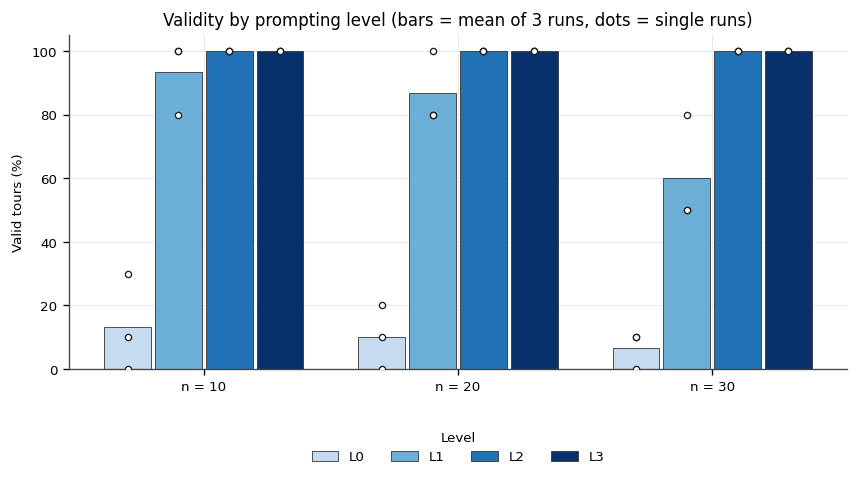

saved fig6_validity_3runs.png


In [ ]:
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

FIG_DIR = RESULTS_DIR.parent / "figures"
runs = {"run1": "llm_calls.jsonl", "run2": "llm_calls_rep2.jsonl", "run3": "llm_calls_rep3.jsonl"}
LV = ["L0", "L1", "L2", "L3"]; SZ = [10, 20, 30]
LCOL = {"L0": "#c6dbef", "L1": "#6baed6", "L2": "#2171b5", "L3": "#08306b"}

D = pd.concat([pd.DataFrame(load_jsonl(LOG_DIR / fn)).assign(run=r) for r, fn in runs.items() if (LOG_DIR / fn).exists()],
              ignore_index=True)
cp = pd.DataFrame(load_jsonl(RESULTS_DIR / "cpsat_results.jsonl")).set_index("instance_id")
nn = pd.read_csv(RESULTS_DIR / "nn_results.csv").set_index("instance_id")

# one row per (run, instance, level): solved?, attempts used, final valid tour length
rows = []
for (run, iid), g in D.groupby(["run", "instance_id"]):
    g = g.set_index(["level", "attempt"]); l1 = g.loc[("L1", 1)]
    for lv in LV:
        if lv in ("L0", "L1"):
            ch = [g.loc[(lv, 1)]]
        else:
            ch, a = [l1], 2
            while (lv, a) in g.index and not ch[-1]["py_valid"]:
                ch.append(g.loc[(lv, a)]); a += 1
        ok = bool(ch[-1]["py_valid"])
        rows.append({"run": run, "instance_id": iid, "level": lv, "n": int(l1["n_cities"]), "valid": ok,
                     "attempts": len(ch), "length": ch[-1]["tour_length"] if ok else np.nan,
                     "l1_failed": not bool(l1["py_valid"])})
R = pd.DataFrame(rows)
nruns = R["run"].nunique(); print("runs:", sorted(R["run"].unique()))

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

# validity: per run, mean, range, pooled 95% Wilson CI
def val_table(sub, key):
    out = []
    for k, g in sub.groupby(key):
        per = g.groupby("run")["valid"].mean() * 100
        kk, nn_ = int(g["valid"].sum()), len(g); lo, hi = wilson(kk, nn_)
        out.append({**(dict(zip(key, k if isinstance(k, tuple) else (k,)))), "pooled_valid": f"{kk}/{nn_}",
                    "mean_%": per.mean(), "min_%": per.min(), "max_%": per.max(),
                    "CI95_lo_%": 100 * lo, "CI95_hi_%": 100 * hi,
                    **{f"{r}_%": v for r, v in per.items()}})
    return pd.DataFrame(out)
V_all = val_table(R, ["level"]); V_sz = val_table(R, ["level", "n"])
V_all.round(1).to_csv(RESULTS_DIR / "table_validity_3runs_overall.csv", index=False)
V_sz.round(1).to_csv(RESULTS_DIR / "table_validity_3runs_by_size.csv", index=False)
print("\n== 1a. Validity, all sizes pooled ==");  display(V_all.round(1))
print("== 1b. Validity by size ==");               display(V_sz.round(1))

# effort: attempts used (L2/L3), and attempts among instances where L1 failed
E = R[R.level.isin(["L2", "L3"])]
eff = E.groupby("level").agg(mean_attempts_all=("attempts", "mean"), max_attempts=("attempts", "max"))
f = E[E.l1_failed].groupby("level").agg(l1_failures=("attempts", "size"), mean_attempts_after_L1_failure=("attempts", "mean"),
                                         max_attempts_after_failure=("attempts", "max"))
eff = eff.join(f); eff.round(2).to_csv(RESULTS_DIR / "table_effort_3runs.csv")
print("\n== 2. Effort (attempt 1 = the shared L1 answer) =="); display(eff.round(2))
fails = E[E.l1_failed].pivot_table(index=["run", "instance_id"], columns="level", values="attempts")
print("L1 failures where L3 needed fewer / equal / more attempts than L2:",
      int((fails.L3 < fails.L2).sum()), "/", int((fails.L3 == fails.L2).sum()), "/", int((fails.L3 > fails.L2).sum()))

# quality (valid subset only, so L0/L1 are selection-biased)
R["cp_len"] = R.instance_id.map(cp["length"]); R["nn_len"] = R.instance_id.map(nn["length"])
R["gap_cp_%"] = 100 * (R.length / R.cp_len - 1)
Q = R[R.valid].groupby(["level", "n"]).agg(valid_tours=("gap_cp_%", "size"), mean_gap_pct=("gap_cp_%", "mean"),
                                           median_gap_pct=("gap_cp_%", "median"), sd=("gap_cp_%", "std")).reset_index()
nng = (100 * (nn["length"] / cp["length"] - 1)).groupby(cp["n_cities"]).mean()
Q.round(1).to_csv(RESULTS_DIR / "table_quality_3runs.csv", index=False)
print("\n== 3. Gap to CP-SAT best (valid tours only; n=30 reference is best-found, not proven) =="); display(Q.round(1))
print("Nearest-neighbour mean gap by n:", nng.round(1).to_dict())

# CP-SAT time: mean and median (so the table is unambiguous)
t = cp.groupby("n_cities")["wall_seconds"].agg(["mean", "median", "max"]).round(3)
print("\n== 4. CP-SAT wall time (s) =="); display(t)

# Figure 6: validity by level and size, bars = mean of runs, dots = individual runs
fig, ax = plt.subplots(figsize=(7.2, 4.2)); w = 0.2
for j, lv in enumerate(LV):
    for i, n in enumerate(SZ):
        per = R[(R.level == lv) & (R.n == n)].groupby("run")["valid"].mean() * 100
        x = i + (j - 1.5) * w
        ax.bar(x, per.mean(), w * 0.92, color=LCOL[lv], edgecolor="#333", linewidth=0.5, label=lv if i == 0 else None)
        ax.scatter([x] * len(per), per.values, s=14, color="white", edgecolor="#222", linewidth=0.8, zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels([f"n = {n}" for n in SZ]); ax.set_ylim(0, 105)
ax.set_ylabel("Valid tours (%)"); ax.set_title(f"Validity by prompting level (bars = mean of {nruns} runs, dots = single runs)", fontsize=10)
ax.legend(title="Level", frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.32))
for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig6_validity_3runs.png", dpi=300, bbox_inches="tight"); plt.show()
print("saved fig6_validity_3runs.png")

In [ ]:

import sys, json, time, importlib, csv
from pathlib import Path
import numpy as np
from ortools.sat.python import cp_model
from ortools.constraint_solver import pywrapcp, routing_enums_pb2

PROJECT_DIR = Path("/content/drive/MyDrive/tsp_precedence")
DATA_DIR, RESULTS_DIR = PROJECT_DIR / "data", PROJECT_DIR / "results"
sys.path.append(str(PROJECT_DIR))
import tsp_utils, cpsat_utils
importlib.reload(tsp_utils); importlib.reload(cpsat_utils)
from tsp_utils import load_jsonl, check_tour, tour_length, DISTANCE_SCALE
from cpsat_utils import validate_with_cpsat

ROUTING_SECONDS = 60      # per routing run 
CPSAT_SECONDS = 180       # tightened CP-SAT run per instance
WORKERS = 2

instances = {i["instance_id"]: i for i in load_jsonl(DATA_DIR / "instances.jsonl")}
cp60 = {r["instance_id"]: r for r in load_jsonl(RESULTS_DIR / "cpsat_results.jsonl")}
nn = {r["instance_id"]: json.loads(r["tour"]) for r in csv.DictReader(open(RESULTS_DIR / "nn_results.csv"))}


def dist_matrix(inst):
    C = np.asarray(inst["coordinates"])
    n = inst["n_cities"]
    return [[int(round(np.linalg.norm(C[i] - C[j]) * DISTANCE_SCALE)) for j in range(n)] for i in range(n)]


def routing_search(inst, start_tour, seconds):
    """OR-Tools routing solver with precedence rules, guided local search from a valid start tour."""
    n, D = inst["n_cities"], dist_matrix(inst)
    man = pywrapcp.RoutingIndexManager(n, 1, 0)
    R = pywrapcp.RoutingModel(man)
    cost = R.RegisterTransitCallback(lambda a, b: D[man.IndexToNode(a)][man.IndexToNode(b)])
    R.SetArcCostEvaluatorOfAllVehicles(cost)
    one = R.RegisterTransitCallback(lambda a, b: 1)
    R.AddDimension(one, 0, n, True, "position")
    pos = R.GetDimensionOrDie("position")
    for a, b in inst["precedences"]:
        R.solver().Add(pos.CumulVar(man.NodeToIndex(a)) < pos.CumulVar(man.NodeToIndex(b)))
    p = pywrapcp.DefaultRoutingSearchParameters()
    p.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    p.time_limit.FromSeconds(int(seconds))
    R.CloseModelWithParameters(p)
    init = R.ReadAssignmentFromRoutes([start_tour[1:-1]], True)
    sol = R.SolveFromAssignmentWithParameters(init, p)
    if sol is None:
        return None
    tour, idx = [], R.Start(0)
    while not R.IsEnd(idx):
        tour.append(man.IndexToNode(idx))
        idx = sol.Value(R.NextVar(idx))
    return tour + [0]


def cpsat_tight(inst, hint_tour, seconds):
    """Same CP-SAT model as before, plus safe pruning implied by the precedence rules, started from a hint."""
    n, D = inst["n_cities"], dist_matrix(inst)
    anc = {c: set() for c in range(n)}                 # all cities that must come before c
    for a, b in inst["precedences"]:
        anc[b].add(a)
    changed = True
    while changed:                                      # transitive closure
        changed = False
        for c in range(n):
            new = set().union(*(anc[p] for p in anc[c])) if anc[c] else set()
            if not new <= anc[c]:
                anc[c] |= new
                changed = True
    desc = {c: {d for d in range(n) if c in anc[d]} for c in range(n)}
    m = cp_model.CpModel()
    x = {}
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            if j != 0 and i in desc[j]:   # j must come before i, so i -> j is impossible
                continue
            if i == 0 and anc[j]:         # j has a prerequisite, so it cannot be first
                continue
            if j == 0 and desc[i]:        # i has a dependant, so it cannot be last
                continue
            x[i, j] = m.NewBoolVar(f"x_{i}_{j}")
    m.AddCircuit([(i, j, v) for (i, j), v in x.items()])
    pos = [m.NewIntVar(0, 0, "p0")] + [m.NewIntVar(1 + len(anc[i]), n - 1 - len(desc[i]), f"p{i}") for i in range(1, n)]
    for (i, j), v in x.items():
        if j != 0:
            m.Add(pos[j] == pos[i] + 1).OnlyEnforceIf(v)
    for a, b in inst["precedences"]:
        m.Add(pos[a] < pos[b])
    m.Minimize(sum(D[i][j] * v for (i, j), v in x.items()))
    hint_arcs = {(hint_tour[k], hint_tour[k + 1]) for k in range(len(hint_tour) - 1)}
    for (i, j), v in x.items():
        m.AddHint(v, (i, j) in hint_arcs)
    s = cp_model.CpSolver()
    s.parameters.max_time_in_seconds = seconds
    s.parameters.num_search_workers = WORKERS
    s.parameters.random_seed = 0
    status = s.Solve(m)
    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return None, s.StatusName(status), None
    succ = {i: j for (i, j), v in x.items() if s.Value(v)}
    tour, cur = [0], 0
    for _ in range(n):
        cur = succ[cur]
        tour.append(cur)
    return tour, s.StatusName(status), s.BestObjectiveBound() / DISTANCE_SCALE


def is_valid(inst, tour):
    ok_py = tour is not None and check_tour(tour, inst["n_cities"], inst["precedences"])["valid"]
    ok_cp = tour is not None and validate_with_cpsat(inst, tour)
    assert ok_py == ok_cp, ("validators disagree", inst["instance_id"])
    return ok_py


ref_path = RESULTS_DIR / "reference_tours.jsonl"
done = {r["instance_id"] for r in load_jsonl(ref_path)} if ref_path.exists() else set()

for iid, inst in instances.items():
    if iid in done:
        continue
    C = inst["coordinates"]
    base = cp60[iid]
    rec = {"instance_id": iid, "n_cities": inst["n_cities"], "cpsat60_length": base["length"],
           "cpsat60_status": base["status"], "candidates": {}}
    if base["status"] == "OPTIMAL":
        rec.update(reference_tour=base["tour"], reference_length=base["length"],
                   reference_source="cpsat60 (proven optimal)", proven_optimal=True,
                   lower_bound=base["bound_length"])
    else:
        cands = {"cpsat60": base["tour"]}
        t0 = time.perf_counter()
        r1 = routing_search(inst, nn[iid], ROUTING_SECONDS)
        if is_valid(inst, r1):
            cands["routing_from_nn"] = r1
        r2 = routing_search(inst, base["tour"], ROUTING_SECONDS)
        if is_valid(inst, r2):
            cands["routing_from_cpsat60"] = r2
        best_so_far = min(cands.values(), key=lambda t: tour_length(C, t))
        r3, status3, bound3 = cpsat_tight(inst, best_so_far, CPSAT_SECONDS)
        if is_valid(inst, r3):
            cands["cpsat_tight"] = r3
        lengths = {k: tour_length(C, t) for k, t in cands.items()}
        best = min(lengths, key=lengths.get)
        lb = max(base["bound_length"], bound3 or 0)
        rec.update(reference_tour=cands[best], reference_length=lengths[best], reference_source=best,
                   proven_optimal=(status3 == "OPTIMAL" and best == "cpsat_tight"),
                   lower_bound=lb, candidates=lengths, search_seconds=time.perf_counter() - t0,
                   settings={"routing_seconds": ROUTING_SECONDS, "cpsat_seconds": CPSAT_SECONDS, "workers": WORKERS})
    with open(ref_path, "a") as f:
        f.write(json.dumps(rec) + "\n")
    print(f"{iid}  ref={rec['reference_length']:.4f}  source={rec['reference_source']:<28}"
          f"  cpsat60 is {100 * (base['length'] / rec['reference_length'] - 1):5.2f}% above it"
          + (f"  | candidates: {', '.join(f'{k}={v:.4f}' for k, v in rec['candidates'].items())}" if rec["candidates"] else ""),
          flush=True)

ref = load_jsonl(ref_path)
print("\nReference tours saved:", len(ref), "of", len(instances), "->", ref_path)
for n in (10, 20, 30):
    rs = [r for r in ref if r["n_cities"] == n]
    if rs:
        above = [100 * (r["cpsat60_length"] / r["reference_length"] - 1) for r in rs]
        print(f"n={n}: proven optimal {sum(r['proven_optimal'] for r in rs)}/{len(rs)} | "
              f"CP-SAT 60-s tour above reference: mean {np.mean(above):.2f}%, max {np.max(above):.2f}%")

n10_00  ref=3.1636  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_01  ref=3.1175  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_02  ref=4.0671  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_03  ref=3.4450  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_04  ref=3.9717  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_05  ref=2.5901  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_06  ref=2.8803  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_07  ref=3.2426  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_08  ref=3.0518  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n10_09  ref=2.7721  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n20_00  ref=4.9353  source=cpsat60 (proven optimal)      cpsat60 is  0.00% above it
n20_01  ref=4.9743  source=cpsat60 (proven optimal)      cpsat60 is  0.00% a

calls per run: {'run1': 78, 'run2': 76, 'run3': 68} | total: 222
model: ['gemini-3.5-flash-lite'] | thinking: ['medium']
  run1: 2026-10-26T09:00:39 -> 2026-10-26T09:20:30 UTC
  run2: 2026-10-26T09:50:02 -> 2026-10-26T10:05:25 UTC
  run3: 2026-10-26T10:05:43 -> 2026-10-26T10:20:44 UTC

== Validator agreement (all calls) ==
 {
  "calls": 222,
  "disagreements": 0,
  "well_formed_replies": 133,
  "valid_replies": 117,
  "well_formed_but_invalid": 16,
  "error_types_of_well_formed_invalid": {
    "precedence": 16
  }
}

== T1. Validity (L0, L1: first answer; L2, L3: within 5 attempts). CI = 95%, resampling instances ==


,level,n,valid,pct,CI95_lo,CI95_hi,run1_pct,run2_pct,run3_pct
0,L0,10,4/30,13.3,0.0,30.0,10.0,30.0,0.0
1,L0,20,3/30,10.0,0.0,23.3,20.0,10.0,0.0
2,L0,30,2/30,6.7,0.0,16.7,10.0,10.0,0.0
3,L0,all,9/90,10.0,3.3,17.8,13.3,16.7,0.0
4,L1,10,28/30,93.3,83.3,100.0,80.0,100.0,100.0
5,L1,20,26/30,86.7,73.3,100.0,100.0,80.0,80.0
6,L1,30,18/30,60.0,46.7,76.7,50.0,50.0,80.0
7,L1,all,72/90,80.0,71.1,88.9,76.7,76.7,86.7
8,L2,10,30/30,100.0,100.0,100.0,100.0,100.0,100.0
9,L2,20,30/30,100.0,100.0,100.0,100.0,100.0,100.0



== T2. Effort (attempt 1 = the shared L1 answer) ==


,mean_attempts_all,max_attempts,l1_failures,mean_attempts_after_l1_failure,L3_fewer_equal_more_than_L2
level,,,,,
L2,1.24,5,18,2.22,2/14/2
L3,1.22,3,18,2.11,2/14/2


Attempt at which the first valid tour came, among L1 failures:


...

,failed_answers,format,structure,coverage,precedence
L0 first answer,81,36,45,2,0
L1 first answer,18,4,0,0,14
L2/L3 retries,6,3,1,1,2



== T6. Cost at list price (actual cost $0, free tier); pooled over all runs ==


,instance_runs,valid,total_usd,mean_usd_per_instance,usd_per_valid_tour,x_vs_L1
level,,,,,,
L0,90,9,1.0490,0.0117,0.1166,12.2496
L1,90,72,0.6851,0.0076,0.0095,1.0000
L2,90,90,0.8138,0.0090,0.0090,0.9503
L3,90,90,0.8072,0.0090,0.0090,0.9426


,calls,input_tokens,output_tokens,thinking_tokens,est_usd,api_minutes
run,,,,,,
run1,78,72833,13595,266570.0,0.72,10.80
run2,76,55574,8957,230516.0,0.62,9.31
run3,68,45664,6600,246877.0,0.65,9.64


total est. USD: 1.99


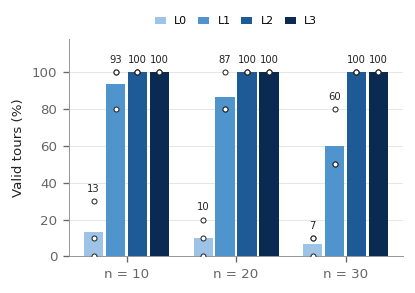

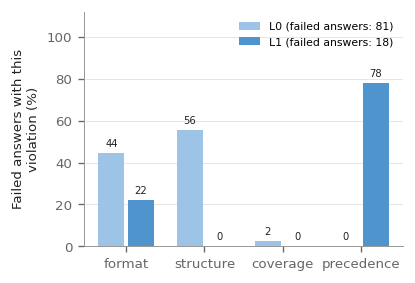

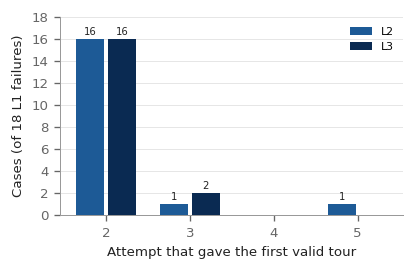

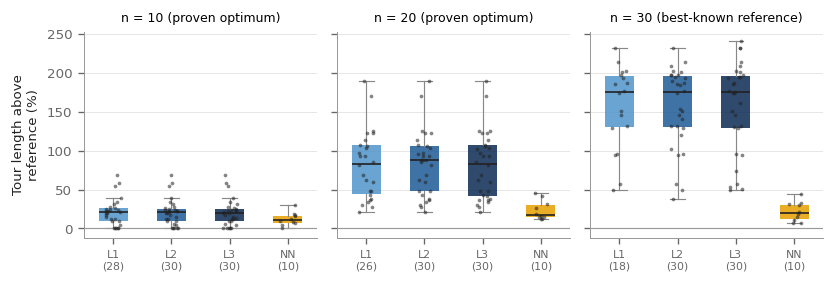

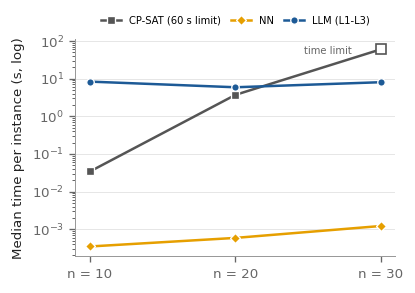


Saved tables to /content/drive/MyDrive/tsp_precedence/results/final and figures to /content/drive/MyDrive/tsp_precedence/figures/final


In [ ]:

import sys, json, importlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
try:
    display
except NameError:
    display = print

PROJECT_DIR = Path("/content/drive/MyDrive/tsp_precedence")
DATA_DIR, LOG_DIR, RESULTS_DIR = PROJECT_DIR / "data", PROJECT_DIR / "logs", PROJECT_DIR / "results"
OUT, FIG = RESULTS_DIR / "final", PROJECT_DIR / "figures" / "final"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
sys.path.append(str(PROJECT_DIR))
import tsp_utils; importlib.reload(tsp_utils)
from tsp_utils import load_jsonl

K = 5
LEVELS = ["L0", "L1", "L2", "L3"]
SIZES = [10, 20, 30]
RUNS = {"run1": "llm_calls.jsonl", "run2": "llm_calls_rep2.jsonl", "run3": "llm_calls_rep3.jsonl"}
PRICE_IN, PRICE_OUT = 0.30, 2.50  

COL = {"L0": "#9dc3e6", "L1": "#4f94cc", "L2": "#1d5a96", "L3": "#0a2a52", "NN": "#E69F00", "CP-SAT": "#555555"}
INK, MUTED = "#222222", "#666666"
plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#999999", "axes.linewidth": 0.6,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.labelcolor": INK, "legend.frameon": False, "figure.dpi": 120})

# load data
D = pd.concat([pd.DataFrame(load_jsonl(LOG_DIR / fn)).assign(run=r) for r, fn in RUNS.items()], ignore_index=True)
for c in ["input_tokens", "output_tokens", "thinking_tokens", "latency_seconds"]:
    D[c] = D[c].fillna(0)
D["usd"] = (D["input_tokens"] * PRICE_IN + (D["output_tokens"] + D["thinking_tokens"]) * PRICE_OUT) / 1e6
cp60 = pd.DataFrame(load_jsonl(RESULTS_DIR / "cpsat_results.jsonl")).set_index("instance_id")
nn = pd.read_csv(RESULTS_DIR / "nn_results.csv").set_index("instance_id")
ref = pd.DataFrame(load_jsonl(RESULTS_DIR / "reference_tours.jsonl")).set_index("instance_id")
assert len(ref) == 30, "Run Cell R first (reference tours for all 30 instances)."
REF = ref["reference_length"]
print("calls per run:", D.groupby("run").size().to_dict(), "| total:", len(D))
print("model:", D["model_id"].unique().tolist(), "| thinking:", D["thinking_level"].unique().tolist())
for r, g in D.groupby("run"):
    print(f"  {r}: {g['timestamp'].min()[:19]} -> {g['timestamp'].max()[:19]} UTC")

# validator agreement, all calls
def well_formed(row):
    t, n = row["parsed_tour"], row["n_cities"]
    return (isinstance(t, list) and len(t) == n + 1 and t[0] == 0 and t[-1] == 0
            and all(isinstance(c, int) and not isinstance(c, bool) and 0 <= c < n for c in t))
D["well_formed"] = D.apply(well_formed, axis=1)
agree = {"calls": len(D), "disagreements": int((D["py_valid"] != D["cpsat_valid"]).sum()),
         "well_formed_replies": int(D["well_formed"].sum()), "valid_replies": int(D["py_valid"].sum()),
         "well_formed_but_invalid": int((D["well_formed"] & ~D["py_valid"]).sum())}
wf_bad = D[D["well_formed"] & ~D["py_valid"]]["error_types"].explode().value_counts().to_dict()
agree["error_types_of_well_formed_invalid"] = wf_bad
json.dump(agree, open(OUT / "validator_agreement.json", "w"), indent=2)
print("\n== Validator agreement (all calls) ==\n", json.dumps(agree, indent=2))

# one row per run x instance x level
rows = []
for (run, iid), g in D.groupby(["run", "instance_id"]):
    g = g.set_index(["level", "attempt"])
    l1 = g.loc[("L1", 1)]
    for lv in LEVELS:
        if lv in ("L0", "L1"):
            ch = [g.loc[(lv, 1)]]
        else:
            ch, a = [l1], 2
            while (lv, a) in g.index and not ch[-1]["py_valid"]:
                ch.append(g.loc[(lv, a)]); a += 1
        ok = bool(ch[-1]["py_valid"])
        assert ok or len(ch) == (1 if lv in ("L0", "L1") else K), f"incomplete chain {run} {iid} {lv}"
        rows.append({"run": run, "instance_id": iid, "n": int(l1["n_cities"]), "level": lv, "valid": ok,
                     "attempts": len(ch), "l1_failed": not bool(l1["py_valid"]),
                     "length": ch[-1]["tour_length"] if ok else np.nan,
                     "llm_seconds": sum(r["latency_seconds"] for r in ch), "usd": sum(r["usd"] for r in ch),
                     "input_tokens": sum(r["input_tokens"] for r in ch),
                     "billed_output_tokens": sum(r["output_tokens"] + r["thinking_tokens"] for r in ch)})
R = pd.DataFrame(rows)
R["gap_pct"] = 100 * (R["length"] / R["instance_id"].map(REF) - 1)
R.to_csv(OUT / "per_run_instance_level.csv", index=False)

# CIs by resampling instances
rng = np.random.default_rng(0)
def boot_ci(sub, B=10000):
    v = sub.groupby("instance_id")["valid"].mean().values      # each instance: share of runs valid
    if v.min() == v.max():
        return 100 * v.mean(), 100 * v.mean()
    bs = rng.choice(v, (B, len(v))).mean(axis=1)
    return 100 * np.percentile(bs, 2.5), 100 * np.percentile(bs, 97.5)

# T1 validity
t1 = []
for lv in LEVELS:
    for n in SIZES + ["all"]:
        sub = R[R["level"] == lv] if n == "all" else R[(R["level"] == lv) & (R["n"] == n)]
        per = sub.groupby("run")["valid"].mean() * 100
        lo, hi = boot_ci(sub)
        t1.append({"level": lv, "n": n, "valid": f"{int(sub['valid'].sum())}/{len(sub)}",
                   "pct": 100 * sub["valid"].mean(), "CI95_lo": lo, "CI95_hi": hi,
                   **{f"{r}_pct": v for r, v in per.items()}})
T1 = pd.DataFrame(t1); T1.round(1).to_csv(OUT / "T1_validity.csv", index=False)
print("\n== T1. Validity (L0, L1: first answer; L2, L3: within 5 attempts). CI = 95%, resampling instances ==")
display(T1.round(1))

# T2 effort
E = R[R["level"].isin(["L2", "L3"])]
T2 = E.groupby("level").agg(mean_attempts_all=("attempts", "mean"), max_attempts=("attempts", "max"))
T2 = T2.join(E[E["l1_failed"]].groupby("level").agg(l1_failures=("attempts", "size"),
                                                     mean_attempts_after_l1_failure=("attempts", "mean")))
cmp = E[E["l1_failed"]].pivot_table(index=["run", "instance_id"], columns="level", values="attempts")
T2["L3_fewer_equal_more_than_L2"] = f"{int((cmp.L3 < cmp.L2).sum())}/{int((cmp.L3 == cmp.L2).sum())}/{int((cmp.L3 > cmp.L2).sum())}"
dist = (E[E["l1_failed"]].groupby(["level", "attempts"]).size().unstack(fill_value=0)
          .reindex(columns=range(2, K + 1), fill_value=0))
T2.round(2).to_csv(OUT / "T2_effort.csv"); dist.to_csv(OUT / "T2b_attempts_after_l1_failure.csv")
print("\n== T2. Effort (attempt 1 = the shared L1 answer) =="); display(T2.round(2))
print("Attempt at which the first valid tour came, among L1 failures:"); display(dist)

#T3 quality vs best-known tour
nn_gap = 100 * (nn["length"] / REF.reindex(nn.index) - 1)
cp_gap = 100 * (cp60["length"] / REF.reindex(cp60.index) - 1)
q = (R[R["valid"]].groupby(["n", "level"])["gap_pct"]
       .agg(valid_tours="count", mean_gap="mean", median_gap="median", sd="std").reset_index())
extra = []
for name, s in [("NN", nn_gap), ("CP-SAT 60s", cp_gap)]:
    for n in SIZES:
        v = s[s.index.str.startswith(f"n{n:02d}_")]
        extra.append({"n": n, "level": name, "valid_tours": len(v), "mean_gap": v.mean(),
                      "median_gap": v.median(), "sd": v.std()})
T3 = pd.concat([q, pd.DataFrame(extra)], ignore_index=True).sort_values(["n", "level"])
T3.round(2).to_csv(OUT / "T3_quality.csv", index=False)
refinfo = ref.groupby("n_cities").agg(proven_optimal=("proven_optimal", "sum"),
                                      mean_ref_length=("reference_length", "mean"))
refinfo["mean_lower_bound_gap_pct"] = (100 * (ref["reference_length"] / ref["lower_bound"] - 1)).groupby(ref["n_cities"]).mean()
refinfo.round(3).to_csv(OUT / "T3b_reference_info.csv")
print("\n== T3. % above best-known tour (valid tours only; L0/L1 are the valid subset only) ==")
display(T3.round(1))
print("Reference tours (n=30: best known, not proven optimal):"); display(refinfo.round(2))

#T4 time
llm_t = R[R["valid"]].groupby(["n", "level"])["llm_seconds"].median().unstack()
T4 = pd.DataFrame({"CP-SAT 60s mean": cp60.groupby("n_cities")["wall_seconds"].mean(),
                   "CP-SAT 60s median": cp60.groupby("n_cities")["wall_seconds"].median(),
                   "CP-SAT proven": cp60.groupby("n_cities")["status"].apply(lambda s: f"{(s == 'OPTIMAL').sum()}/{len(s)}"),
                   "NN median": nn.groupby("n_cities")["runtime_seconds"].median()})
T4 = T4.join(llm_t.add_suffix(" median"))
T4.index.name = "n"; T4.round(3).to_csv(OUT / "T4_time.csv")
print("\n== T4. Time in seconds (LLM = sum of API latencies until the valid tour; pauses excluded) ==")
display(T4.round(3))

#T5 why answers fail (pooled)
CATEGORY = {"not_json": "format", "empty_reply": "format", "no_tour_key": "format", "tour_not_a_list": "format",
            "not_a_list": "format", "non_integer": "format", "wrong_length": "structure",
            "wrong_start": "structure", "wrong_end": "structure", "out_of_range": "structure",
            "missing": "coverage", "duplicate": "coverage", "precedence": "precedence"}
CATS = ["format", "structure", "coverage", "precedence"]
f = D[~D["py_valid"]].copy()
f["group"] = np.where(f["attempt"] == 1, f["level"] + " first answer", "L2/L3 retries")
f["cats"] = f["error_types"].apply(lambda ts: {CATEGORY.get(t, "other") for t in ts})
T5 = pd.DataFrame({grp: {"failed_answers": len(gg), **{c: int(gg["cats"].apply(lambda s, c=c: c in s).sum()) for c in CATS}}
                   for grp, gg in f.groupby("group")}).T
T5.to_csv(OUT / "T5_failure_categories.csv")
print("\n== T5. Failed answers by violation category (one answer can have several) =="); display(T5)

# T6 cost (pooled)
T6 = R.groupby("level").agg(instance_runs=("usd", "size"), valid=("valid", "sum"), total_usd=("usd", "sum"),
                            mean_usd_per_instance=("usd", "mean"))
T6["usd_per_valid_tour"] = T6["total_usd"] / T6["valid"]
T6["x_vs_L1"] = T6["usd_per_valid_tour"] / T6.loc["L1", "usd_per_valid_tour"]
T6b = D.groupby("run").agg(calls=("usd", "size"), input_tokens=("input_tokens", "sum"),
                           output_tokens=("output_tokens", "sum"), thinking_tokens=("thinking_tokens", "sum"),
                           est_usd=("usd", "sum"), api_minutes=("latency_seconds", lambda s: s.sum() / 60))
T6.round(4).to_csv(OUT / "T6_cost_by_level.csv"); T6b.round(2).to_csv(OUT / "T6b_cost_by_run.csv")
print("\n== T6. Cost at list price (actual cost $0, free tier); pooled over all runs =="); display(T6.round(4))
display(T6b.round(2)); print("total est. USD:", round(D["usd"].sum(), 2))

# figures
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=300, bbox_inches="tight"); plt.show()

# Fig 1: validity by level and size; bars = pooled, dots = single runs
fig, ax = plt.subplots(figsize=(3.5, 2.5)); w = 0.2
for j, lv in enumerate(LEVELS):
    for i, n in enumerate(SIZES):
        sub = R[(R["level"] == lv) & (R["n"] == n)]
        x = i + (j - 1.5) * w; v = 100 * sub["valid"].mean()
        ax.bar(x, v, w * 0.88, color=COL[lv], label=lv if i == 0 else None)
        per = sub.groupby("run")["valid"].mean() * 100
        ax.scatter([x] * len(per), per.values, s=9, facecolor="white", edgecolor=INK, linewidth=0.6, zorder=3)
        ax.text(x, max(v, per.max()) + 4, f"{v:.0f}", ha="center", va="bottom", fontsize=6, color=INK)
ax.set_xticks(range(3)); ax.set_xticklabels([f"n = {n}" for n in SIZES]); ax.set_ylim(0, 118)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("Valid tours (%)")
ax.legend(ncol=4, fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, 1.15), columnspacing=1, handlelength=1)
save(fig, "fig1_validity.png")

# Fig 2: what goes wrong in failed first answers (L0 vs L1)
fig, ax = plt.subplots(figsize=(3.5, 2.4)); w = 0.38
for j, lv in enumerate(["L0", "L1"]):
    grp = f"{lv} first answer"; tot = T5.loc[grp, "failed_answers"]
    vals = [100 * T5.loc[grp, c] / tot for c in CATS]; xs = np.arange(len(CATS)) + (j - 0.5) * w
    ax.bar(xs, vals, w * 0.88, color=COL[lv], label=f"{lv} (failed answers: {int(tot)})")
    for x, v in zip(xs, vals):
        ax.text(x, v + 2, f"{v:.0f}", ha="center", va="bottom", fontsize=6, color=INK)
ax.set_xticks(range(len(CATS))); ax.set_xticklabels(CATS); ax.set_ylim(0, 112)
ax.set_ylabel("Failed answers with this\nviolation (%)"); ax.legend(fontsize=6.5, loc="upper right")
save(fig, "fig2_failure_types.png")

# Fig 3: when the first valid tour came, among L1 failures
fig, ax = plt.subplots(figsize=(3.5, 2.3)); w = 0.38
for j, lv in enumerate(["L2", "L3"]):
    vals = [int(dist.loc[lv, a]) for a in range(2, K + 1)]; xs = np.arange(2, K + 1) + (j - 0.5) * w
    ax.bar(xs, vals, w * 0.88, color=COL[lv], label=lv)
    for x, v in zip(xs, vals):
        if v:
            ax.text(x, v + 0.2, str(v), ha="center", va="bottom", fontsize=6, color=INK)
nf = int(E[E["l1_failed"]].groupby("level").size().iloc[0])
ax.set_xticks(range(2, K + 1)); ax.set_xlabel("Attempt that gave the first valid tour")
ax.set_ylabel(f"Cases (of {nf} L1 failures)"); ax.legend(fontsize=6.5)
from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True)); ax.set_ylim(0, dist.values.max() + 2)
save(fig, "fig3_attempts.png")

# Fig 4: tour quality vs best-known tour (valid tours, all runs)
order = ["L1", "L2", "L3", "NN"]
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.4), sharey=True); jit = np.random.default_rng(0)
for ax, n in zip(axes, SIZES):
    data = [R[(R["n"] == n) & (R["level"] == m) & R["valid"]]["gap_pct"].values for m in order[:3]]
    data.append(nn_gap[nn_gap.index.str.startswith(f"n{n:02d}_")].values)
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False, medianprops={"color": INK, "linewidth": 1})
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(COL[m]); patch.set_edgecolor("none"); patch.set_alpha(0.85)
    for part in ("whiskers", "caps"):
        for line in bp[part]:
            line.set_color("#888888"); line.set_linewidth(0.7)
    for i, s in enumerate(data):
        ax.scatter(1 + i + jit.uniform(-0.13, 0.13, len(s)), s, s=5, color=INK, alpha=0.55, zorder=3, linewidths=0)
    ax.axhline(0, color="#999999", linewidth=0.7)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels([f"{m}\n({len(s)})" for m, s in zip(order, data)], fontsize=6.5)
    ax.set_title(f"n = {n}" + (" (best-known reference)" if n == 30 else " (proven optimum)"), fontsize=7.5)
axes[0].set_ylabel("Tour length above\nreference (%)")
save(fig, "fig4_gap.png")

# Fig 5: time per instance (log scale), medians
fig, ax = plt.subplots(figsize=(3.5, 2.5))


llm_all = R[R["valid"] & R["level"].isin(["L1", "L2", "L3"])].groupby("n")["llm_seconds"].median()
series = [("CP-SAT (60 s limit)", T4["CP-SAT 60s median"], COL["CP-SAT"], "s"),
          ("NN", T4["NN median"], COL["NN"], "D"), ("LLM (L1-L3)", llm_all, COL["L2"], "o")]
for name, s, c, mk in series:
    ax.plot(SIZES, [s.get(n, np.nan) for n in SIZES], color=c, marker=mk, markersize=4.5, linewidth=1.5,
            markeredgecolor="white", markeredgewidth=0.8, label=name)
ax.plot([30], [T4["CP-SAT 60s median"].get(30)], marker="s", markersize=5.5, markerfacecolor="white",
        markeredgecolor=COL["CP-SAT"], linestyle="none")
ax.annotate("time limit", (30, T4["CP-SAT 60s median"].get(30)), textcoords="offset points", xytext=(-46, -3),
            fontsize=6, color=MUTED)
ax.set_yscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([f"n = {n}" for n in SIZES])
ax.set_ylabel("Median time per instance (s, log)")
ax.legend(ncol=3, fontsize=6, loc="upper center", bbox_to_anchor=(0.5, 1.15), columnspacing=1, handlelength=2)
save(fig, "fig5_time.png")

print("\nSaved tables to", OUT, "and figures to", FIG)